# Proyecto Final – Gestión de Datos
## Monitoreo de la reputación de Banco Davivienda a partir de las quejas de sus clientes (datos.gov.co)

**Integrantes:** Luis Alberto Banda, Maria Camila Rincón, Juan Pablo Marin, Gabriel Camilo Velasquez y Juan Camilo Guerrero.

Este notebook se ejecuta dentro del contenedor Docker del repositorio (Jupyter Lab, imagen `quay.io/jupyter/scipy-notebook`).

## 0. Configuración del entorno
Importación de librerías autorizadas, verificación de versiones y definición de rutas de trabajo.

In [1]:
# Librerías autorizadas para el proyecto
import json
import sqlite3
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import pyarrow
from jsonpath_ng import parse as jsonpath_parse
from dotenv import load_dotenv

# Se imprimen las versiones para dejar trazabilidad del entorno
for lib in ["pandas", "numpy", "scipy", "matplotlib", "seaborn", "requests", "pyarrow", "jsonpath-ng", "python-dotenv"]:
    print(f"{lib:15s} {version(lib)}")
print(f"{'sqlite3':15s} {sqlite3.sqlite_version}")

pandas          3.1.1
numpy           2.5.4
scipy           1.18.1
matplotlib      3.11.2
seaborn         0.13.2
requests        2.34.2
pyarrow         26.0.1
jsonpath-ng     1.16.0
python-dotenv   1.2.4
sqlite3         3.54.1


In [2]:
# Rutas de trabajo: en el contenedor la carpeta ./work se monta en /home/jovyan/work
WORK_DIR = Path.home() / "work"
RAW_DIR = WORK_DIR / "data" / "raw"
PROCESSED_DIR = WORK_DIR / "data" / "processed"
DB_PATH = WORK_DIR / "reputacion_davivienda.db"

for carpeta in (RAW_DIR, PROCESSED_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

# Variables de entorno opcionales (las APIs SODA2 de datos.gov.co no requieren clave)
load_dotenv()

# Endpoints SODA2 de datos.gov.co definidos para el proyecto
APIS = {
    "6cat-2gcs": "https://www.datos.gov.co/resource/6cat-2gcs.json",
    "xyy7-rn7p": "https://www.datos.gov.co/resource/xyy7-rn7p.json",
    "sr9n-792w": "https://www.datos.gov.co/resource/sr9n-792w.json",
}
print("Carpeta de trabajo:", WORK_DIR, "| existe:", WORK_DIR.exists())

Carpeta de trabajo: /home/jovyan/work | existe: True


## 1. Elevator Pitch

**Marca objeto de estudio:** Banco Davivienda S.A.
**Idea central:** las quejas que los clientes radican ante el banco, el Defensor del Consumidor Financiero y la Superintendencia Financiera son una medida pública, periódica y comparable de la percepción de la marca. Monitorearlas permite anticipar crisis de reputación y saber dónde actuar.

**Fecha de corte de los datos:** descargados el 16/11/2026 (punto 2). Las quejas cubren de enero de 2023 a septiembre de 2026; febrero de 2026 no tiene datos y septiembre de 2026 está incompleto (puntos 4 y 5.1).

> Las cifras de esta sección provienen de las celdas de los puntos 4, 5 y 6 de este notebook.

### 1.1 Preguntas planteadas

**Pregunta 1. Evolución y posición frente al sector.**
¿Cómo ha evolucionado la cantidad de quejas contra Banco Davivienda entre 2023 y 2026, y la marca está ganando o perdiendo participación dentro de las quejas de los bancos del país?

**Pregunta 2. Causas de la insatisfacción.**
¿Qué productos y qué motivos concentran las quejas de Davivienda, y cuáles pesan más en la marca que en los demás bancos (problemas propios) frente a los que son comunes a todo el sector?

**Pregunta 3. Gestión de la queja y territorio.**
¿Qué proporción de las quejas sale del banco hacia el Defensor del Consumidor o la Superintendencia Financiera, y en qué departamentos se concentra la insatisfacción?

### 1.2 Justificación de la importancia de las preguntas

**Por qué Davivienda.** Es el segundo banco con más quejas del país: 1.198.279 entre enero de 2023 y septiembre de 2026, el 14,07 % de las 8.513.837 quejas recibidas por los 31 bancos. Una marca con ese volumen de reclamos está expuesta a un riesgo reputacional que vale la pena medir de forma continua.

**Pregunta 1: permite distinguir un problema de la marca de una tendencia del sector.**
- El promedio mensual de quejas de Davivienda pasó de 22.841 en 2023 a 28.590 en 2024 (+25,2 %), se mantuvo en 2025 (28.779) y volvió a subir en los meses completos de 2026 (33.559, +16,6 %).
- Su participación dentro de las quejas a bancos bajó de 18,2 % en 2023 a 12,5 % en 2025, pero repuntó a 14,9 % en 2026. Es decir, en 2024 y 2025 las quejas de Davivienda crecieron menos que las del resto, y en 2026 crecen más.
- Responder esta pregunta le indica a la empresa si el deterioro reciente es propio y si requiere una acción inmediata.

**Pregunta 2: indica dónde invertir para reducir las quejas.**
- El 55,6 % de las quejas de Davivienda corresponde a fraude y seguridad (transacciones no reconocidas, suplantación), frente al 29,8 % en los demás bancos. Además, ese peso creció de 31,8 % en enero de 2023 a más de 60 % en 2026.
- Las tarjetas de crédito concentran el 32,8 % de las quejas de la marca, casi el doble que en los demás bancos (16,8 %).
- Saber qué problemas son propios de la marca permite priorizar: no es lo mismo una falla general del sistema financiero que una debilidad específica de Davivienda.

**Pregunta 3: mide la calidad de la respuesta y permite focalizar por territorio.**
- El 89,3 % de las quejas se radica directamente en el banco; el 6,2 % llega a la Superintendencia Financiera (5,4 % en los demás bancos) y el 4,4 % al Defensor del Consumidor. Una queja que sale del banco es más costosa y más visible para el regulador. La buena noticia es que esa proporción bajó de 8,5 % en 2023 a 5,5 % en los meses completos de 2026, en línea con los demás bancos.
- Bogotá concentra el 63,9 % de las quejas de Davivienda, frente al 27,6 % en los demás bancos.
- Con esta respuesta la empresa puede dirigir recursos de atención a los territorios y canales donde la insatisfacción es mayor.

**Contribución.** Las tres preguntas juntas convierten un registro administrativo en un tablero de reputación: cuánto se quejan los clientes, de qué, y qué tan bien responde el banco. Esto apoya un proceso existente (la gestión de peticiones, quejas y reclamos) con evidencia comparativa frente a los pares.

### 1.3 Venta del proyecto
*Pendiente: se redactará al final, cuando estén listos el análisis y las visualizaciones, para que guarde relación con los resultados.*

## 2. Carga de datos principales
Los datos principales del proyecto son los que permiten medir la reputación de la marca a partir de las quejas de sus clientes:

| Fuente | Conjunto de datos (datos.gov.co) | Rol |
|---|---|---|
| `xyy7-rn7p` | Quejas interpuestas por los consumidores financieros contra las entidades vigiladas (Smartsupervision) | Hechos: cantidad de quejas por entidad, producto, motivo, instancia, territorio y mes |
| `sr9n-792w` | Entidades vigiladas por la Superintendencia Financiera | Directorio: permite identificar la marca (razón social, NIT) a partir de los códigos `tipo_entidad` + `cod_entidad` |

La descarga se hace completa, paginando la API SODA2 y con reintentos; se guarda una copia cruda en `work/data/raw` para no repetir la descarga.

In [3]:
# Carga de datos principales: quejas y directorio de entidades vigiladas
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

TAM_PAGINA = 50_000  # máximo de registros por petición en SODA2

# Sesión HTTP con reintentos automáticos (espera creciente) ante cortes de red o errores del servidor
sesion = requests.Session()
sesion.mount("https://", HTTPAdapter(max_retries=Retry(
    total=6, backoff_factor=2, status_forcelist=(429, 500, 502, 503, 504), allowed_methods=("GET",))))

def descargar_completo(nombre: str, url: str) -> pd.DataFrame:
    """Descarga todos los registros de un endpoint SODA2 paginando con $limit/$offset.
    Guarda una copia cruda (sin transformar) en RAW_DIR para no repetir la descarga."""
    cache = RAW_DIR / f"{nombre}.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    paginas, offset = [], 0
    while True:
        r = sesion.get(url, params={"$limit": TAM_PAGINA, "$offset": offset, "$order": ":id"}, timeout=300)
        r.raise_for_status()
        lote = r.json()
        if not lote:
            break
        paginas.append(pd.DataFrame(lote))
        offset += len(lote)
        if len(lote) < TAM_PAGINA:
            break
    df = pd.concat(paginas, ignore_index=True).astype("string")
    df.to_parquet(cache, index=False)
    return df

def tipar_numericos(df: pd.DataFrame) -> pd.DataFrame:
    """Convierte a numérico solo las columnas cuyos valores no nulos son 100 % numéricos.
    Las columnas de texto (incluidos los montos con '$') se conservan como texto."""
    df = df.copy()
    for col in df.columns:
        convertida = pd.to_numeric(df[col], errors="coerce")
        if convertida.notna().sum() == df[col].notna().sum():
            # Si todos los valores son enteros se almacena como entero (admite nulos)
            es_entero = convertida.dropna().eq(convertida.dropna().round()).all()
            df[col] = convertida.astype("Int64") if es_entero else convertida
    return df

FUENTES_PRINCIPALES = {"xyy7-rn7p": "Quejas de consumidores financieros", "sr9n-792w": "Entidades vigiladas por la Superfinanciera"}
tablas = {}  # diccionario con todas las tablas cargadas (se usa en la exploración del punto 4)
for nombre, descripcion in FUENTES_PRINCIPALES.items():
    tablas[nombre] = tipar_numericos(descargar_completo(nombre, APIS[nombre]))
    print(f"{nombre} ({descripcion}): {tablas[nombre].shape[0]:,} filas x {tablas[nombre].shape[1]} columnas")

quejas_raw, entidades_raw = tablas["xyy7-rn7p"], tablas["sr9n-792w"]

# Fecha de corte: día en que se descargaron los datos (fecha de creación de la copia cruda) y periodo cubierto
import datetime as dt
def fecha_descarga(nombre: str) -> dt.date:
    return dt.datetime.fromtimestamp((RAW_DIR / f"{nombre}.parquet").stat().st_mtime).date()

FECHA_CORTE = max(fecha_descarga(n) for n in FUENTES_PRINCIPALES).strftime("%d/%m/%Y")
periodos_quejas = quejas_raw["a_o_creacion"] * 100 + quejas_raw["mes_creacion"]
PERIODO_QUEJAS = (f"{periodos_quejas.min() % 100:02d}/{periodos_quejas.min() // 100} a "
                  f"{periodos_quejas.max() % 100:02d}/{periodos_quejas.max() // 100}")
print(f"\nFecha de corte (descarga de los datos principales): {FECHA_CORTE}")
print(f"Periodo cubierto por las quejas (mes/año): {PERIODO_QUEJAS}")

# Identificación de la marca objeto de estudio en el directorio de entidades vigiladas
TIPO_BANCO = 1  # tipo_entidad = 1 corresponde a los establecimientos bancarios
MARCA = "BANCO DAVIVIENDA"
fila_marca = entidades_raw[(entidades_raw["tipo_entidad"] == TIPO_BANCO)
                           & entidades_raw["razon_social"].str.upper().str.contains("DAVIVIENDA")]
assert len(fila_marca) == 1, "Se esperaba exactamente un banco con la marca buscada"
COD_MARCA = int(fila_marca["cod_entidad"].iloc[0])
print(f"\nMarca: {MARCA} -> tipo_entidad = {TIPO_BANCO}, cod_entidad = {COD_MARCA}")

with pd.option_context("display.max_columns", None, "display.width", 250, "display.max_colwidth", 60):
    display(fila_marca)
    display(quejas_raw.head())
    display(entidades_raw.head())

xyy7-rn7p (Quejas de consumidores financieros): 1,400,425 filas x 10 columnas
sr9n-792w (Entidades vigiladas por la Superfinanciera): 456 filas x 10 columnas

Fecha de corte (descarga de los datos principales): 16/11/2026
Periodo cubierto por las quejas (mes/año): 01/2023 a 09/2026

Marca: BANCO DAVIVIENDA -> tipo_entidad = 1, cod_entidad = 39


,tipo_entidad,cod_entidad,razon_social,direccion,ciudad,numeroidentificacion,nombrepublicocargo,representante_legal,emailprincipal,uripaginaweb
9,1,39,BANCO DAVIVIENDA S.A. o BANCO DAVIVIENDA,Avenida El Dorado No. 68 B 31 Piso 1,BOGOTÁ D.C.,8600343137,Presidente,JAVIER JOSÉ SUÁREZ ESPARRAGOZA,notificacionesjudiciales@davivienda.co,Pendiente


,a_o_creacion,mes_creacion,tipo_entidad,codigo_entidad,instancia_recepcion,motivo,producto,departamento,municipio,cantidad_quejas_recibidas
0,2025,11,14,33,Entidad vigilada,Información o asesoría incompleta y/o errada,Seguro de riesgos laborales,"BOGOTÁ, D.C.","BOGOTÁ, D.C.",6
1,2025,11,1,54,Entidad vigilada,No disponibilidad o fallas de los canales de atención,Otros productos de Establecimientos de Crédito y SEDPE,BOLÍVAR,CÓRDOBA,1
2,2025,11,25,14,Entidad vigilada,No disponibilidad o fallas de los canales de atención,Pensiones obligatorias - Vejez,VALLE DEL CAUCA,CALI,2
3,2025,11,1,39,Entidad vigilada,Inconsistencias en el movimiento y saldo total del producto,Cuenta de ahorro,META,VILLAVICENCIO,1
4,2025,11,1,6,Entidad vigilada,No disponibilidad o fallas de los canales de atención,Creditos de consumo,"BOGOTÁ, D.C.","BOGOTÁ, D.C.",1


,tipo_entidad,cod_entidad,razon_social,direccion,ciudad,numeroidentificacion,nombrepublicocargo,representante_legal,emailprincipal,uripaginaweb
0,1,1,BANCO DE BOGOTÁ S.A.,Calle 36 No. 7 - 47.,BOGOTÁ D.C.,8600029644,Presidente,MARÍA FERNANDA SUÁREZ LONDOÑO,rjudicial@bancodebogota.com.co,www.bancodebogota.com.co
1,1,2,BANCO POPULAR S.A.,Calle 17 No. 7 - 35 piso 1,BOGOTÁ D.C.,8600077389,"Presidente -S.p. art. 164 C. Co., con radicado No 202625...",MARÍA FERNANDA SUÁREZ LONDOÑO,presidencia@bancopopular.com.co,www.bancopopular.com.co
2,1,6,"Itaú Colombia S.A., es una sociedad comercial anónima, d...",Carrera 7 No. 99-53 Piso 18,BOGOTÁ D.C.,8909039370,Presidente,JORGE ALBERTO VILLA LOPEZ,Notificaciones.juridico@itau.co,www.bancocorpbanca.com.co
3,1,7,BANCOLOMBIA S.A. podrá girar también con la denominación...,Carrera 48 No.26-85 Avenida los Industriales.,MEDELLIN,8909039388,Presidente,JUAN CARLOS MORA URIBE,gciari@bancolombia.com.co,www.bancolombia.com.co
4,1,9,CITIBANK-COLOMBIA Podrá utilizar solamente la expresión ...,Carrera 9 A No. 99-02 Piso 3,BOGOTÁ D.C.,8600511354,Presidente,ELIZABETH REY DÍAZ,legalnotificaciones@citi.com,Pendiente


## 3. Carga y justificación de datos complementarios

**Fuente:** `6cat-2gcs` – 10.000 empresas más grandes del país (estados financieros por año de corte, 2021 a 2025).

### Justificación de su inclusión
Las quejas miden la percepción de los clientes, pero no dicen nada del tamaño ni de la situación financiera de la organización que responde por la marca, ni del peso económico de cada territorio. Esta fuente aporta ese contexto:

1. **Contexto financiero de la matriz.** Banco Davivienda no aparece en la tabla (no incluye establecimientos bancarios), pero sí su matriz, **Grupo Bolívar S.A.**, con ingresos, ganancia, activos, pasivos y patrimonio de los cinco años. Permite leer la evolución de las quejas junto con el desempeño del grupo.
2. **Contexto económico del territorio.** El número de grandes empresas y sus ingresos por departamento sirven como referencia del tamaño económico de cada territorio, para saber si las quejas se concentran donde hay más actividad o si hay departamentos con más quejas de las esperadas (pregunta 3).

### Estrategia de integración con los datos principales

| Llave | Datos principales | Datos complementarios | Uso |
|---|---|---|---|
| NIT | `numeroidentificacion` del directorio de entidades, **sin el dígito de verificación** | `nit` | Ubicar a Grupo Bolívar S.A. y traer sus cifras por año |
| Año | `a_o_creacion` de las quejas | `a_o_de_corte` | Unir el resumen anual de quejas con las cifras de la matriz |
| Departamento | `departamento` de las quejas | `departamento_domicilio`, homologado | Agregar el contexto empresarial a las quejas por departamento |

### Limitaciones
- El cruce por NIT solo es posible para 10 de las 456 entidades vigiladas (la siguiente celda lo verifica), y las cifras son de la matriz, no del banco.
- Los datos son anuales y llegan hasta 2025, mientras que las quejas son mensuales y llegan hasta 2026: solo coinciden los años 2023 a 2025.
- La unidad de los montos no está documentada en los datos (valores con dos decimales); debe confirmarse en la ficha del conjunto de datos.
- Los nombres de departamento no coinciden entre fuentes y requieren homologación (se hace en el punto 5.1).

In [4]:
# Carga de datos complementarios: 10.000 empresas más grandes del país
tablas["6cat-2gcs"] = tipar_numericos(descargar_completo("6cat-2gcs", APIS["6cat-2gcs"]))
empresas_raw = tablas["6cat-2gcs"]
print(f"6cat-2gcs (10.000 empresas más grandes del país): {empresas_raw.shape[0]:,} filas x {empresas_raw.shape[1]} columnas")
print(f"Fecha de descarga: {fecha_descarga('6cat-2gcs'):%d/%m/%Y} | años de corte: "
      f"{empresas_raw['a_o_de_corte'].min()} a {empresas_raw['a_o_de_corte'].max()}")

# Verificación de la llave de integración: NIT de la entidad vigilada sin dígito de verificación = NIT de la empresa
nit_entidad = entidades_raw["numeroidentificacion"].astype("Int64")
puente = entidades_raw.assign(nit_base=(nit_entidad // 10).where(nit_entidad != 0))
cruce_nit = puente.merge(empresas_raw[["nit", "raz_n_social"]].drop_duplicates("nit"),
                         left_on="nit_base", right_on="nit", how="inner")
print(f"Entidades vigiladas que cruzan por NIT con la tabla de empresas: {len(cruce_nit)} de {len(entidades_raw)}")

with pd.option_context("display.max_columns", None, "display.width", 250, "display.max_colwidth", 60):
    display(cruce_nit[["tipo_entidad", "cod_entidad", "razon_social", "nit_base", "raz_n_social"]])
    # Matriz de la marca: Grupo Bolívar S.A.
    nit_grupo_bolivar = cruce_nit.loc[cruce_nit["razon_social"].str.contains("Bolívar"), "nit_base"].iloc[0]
    display(empresas_raw[empresas_raw["nit"] == nit_grupo_bolivar].sort_values("a_o_de_corte"))

6cat-2gcs (10.000 empresas más grandes del país): 50,000 filas x 14 columnas
Fecha de descarga: 16/11/2026 | años de corte: 2021 a 2025
Entidades vigiladas que cruzan por NIT con la tabla de empresas: 10 de 456


,tipo_entidad,cod_entidad,razon_social,nit_base,raz_n_social
0,5,12,FIDUCIARIA LA PREVISORA S.A. la cual podrá usar la sigla...,860525148,FIDUPREVISORA FONDO DE PRESTACIONES SOCIALES DEL MAGISTERIO
1,6,5,ALMACENES GENERALES DE DEPOSITO ALMAVIVA S.A.,860002153,ALMACENES GENERALES DE DEPOSITO ALMAVIVA S.A.
2,118,10,GOU Payments S.A. EASPBV,800143407,A TODA HORA S.A.
3,142,1,Grupo Aval Acciones y Valores,800216181,GRUPO AVAL ACCIONES Y VALORES S.A.
4,142,2,Grupo de Inversiones Suramericana S.A.,811012271,GRUPO DE INVERSIONES SURAMERICANA S.A.
5,142,3,Grupo Bolívar S.A.,830025448,GRUPO BOLIVAR S. A.
6,142,4,INVERSORA FUNDACIÓN GRUPO SOCIAL S.A.S.,901196014,INVERSORA FUNDACION GRUPO SOCIAL S.A.S.
7,142,6,Skandia Holding de Colombia S.A.,800172954,SKANDIA HOLDING DE COLOMBIA S.A.
8,142,7,Credicorp Capital Holding Colombia S.A.S.,900509577,CREDICORP HOLDING COLOMBIA S.A.S.
9,142,14,Grupo Bicentenario S.A.S,901351676,GRUPO BICENTENARIO S.A.S.


,nit,raz_n_social,supervisor,regi_n,departamento_domicilio,ciudad_domicilio,ciiu,macrosector,ingresos_operacionales,ganancia_p_rdida,total_activos,total_pasivos,total_patrimonio,a_o_de_corte
41662,830025448,GRUPO BOLIVAR S. A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",6492,SERVICIOS,$1.02,$0.97,$13.80,$1.61,$12.19,2021
38970,830025448,GRUPO BOLIVAR S. A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",6492,SERVICIOS,$1.39,$1.18,$14.91,$1.76,$13.14,2022
29756,830025448,GRUPO BOLIVAR S. A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",6492,SERVICIOS,$1.09,$1.49,$16.22,$2.11,$14.11,2023
19332,830025448,GRUPO BOLIVAR S. A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",6492,SERVICIOS,$1.58,$1.80,$16.64,$1.68,$14.95,2024
285,830025448,GRUPO BOLIVAR S. A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",6492,SERVICIOS,$ 0.94,$ 0.88,$ 15.96,$ 1.39,$ 14.56,2025


## 4. Exploración de los datos
En este punto se evalúan las tres fuentes tal como llegan de las APIs, sin filtrar por la marca: el objetivo es conocer su estructura, su comportamiento estadístico y su calidad antes de prepararlas (punto 5).

| Ítem del enunciado | Subsección |
|---|---|
| Inventario descriptivo de los conjuntos de datos | Inventario descriptivo y perfil por atributo |
| Tendencia central, dispersión, tablas de contingencia y sesgo | Análisis de tendencia central, dispersión, tablas de contingencia y sesgo |
| Correlación y covarianza | Correlación y covarianza entre los datos |
| Análisis de calidad de los datos | Análisis de calidad de los datos |

Cada subsección termina con una interpretación de sus resultados.

### Inventario descriptivo de los conjuntos de datos
Resumen de cada fuente a nivel de conjunto: quién la publica, qué representa cada fila, tamaño, periodo cubierto y frecuencia de actualización. Los metadatos se consultan en el portal datos.gov.co y se guardan junto a la copia cruda para que el inventario sea reproducible.

In [ ]:
# ============================================================
# Inventario descriptivo por conjunto de datos
# ============================================================
def metadatos(nombre: str) -> dict:
    """Metadatos del conjunto en datos.gov.co; se guardan en RAW_DIR la primera vez para no repetir la consulta."""
    cache = RAW_DIR / f"{nombre}_metadatos.json"
    if not cache.exists():
        r = sesion.get(f"https://www.datos.gov.co/api/views/{nombre}.json", timeout=60)
        r.raise_for_status()
        cache.write_text(json.dumps(r.json(), ensure_ascii=False), encoding="utf-8")
    return json.loads(cache.read_text(encoding="utf-8"))

# Descripción de cada fuente según su rol en el proyecto
DESCRIPCION = {
    "xyy7-rn7p": {"rol": "Principal",
                  "granularidad": "Entidad × producto × motivo × instancia × municipio × mes (con la cantidad de quejas)",
                  "llave": "tipo_entidad + codigo_entidad"},
    "sr9n-792w": {"rol": "Principal",
                  "granularidad": "Una fila por entidad vigilada",
                  "llave": "tipo_entidad + cod_entidad; NIT sin dígito de verificación"},
    "6cat-2gcs": {"rol": "Complementario",
                  "granularidad": "Una fila por empresa y año de corte",
                  "llave": "nit + a_o_de_corte"},
}

def periodo(nombre: str, df: pd.DataFrame) -> str:
    if nombre == "xyy7-rn7p":
        return PERIODO_QUEJAS + " (mensual)"
    if nombre == "6cat-2gcs":
        return f"{df['a_o_de_corte'].min()} a {df['a_o_de_corte'].max()} (anual)"
    return "Sin dimensión temporal (directorio vigente)"

def unidades(nombre: str, df: pd.DataFrame) -> str:
    if nombre == "xyy7-rn7p":
        return (f"{df[['tipo_entidad', 'codigo_entidad']].drop_duplicates().shape[0]} entidades; "
                f"{df['cantidad_quejas_recibidas'].sum():,} quejas")
    if nombre == "sr9n-792w":
        return f"{df['tipo_entidad'].nunique()} tipos de entidad"
    return f"{df['nit'].nunique():,} empresas distintas"

filas = []
for nombre in ["xyy7-rn7p", "sr9n-792w", "6cat-2gcs"]:
    df, meta = tablas[nombre], metadatos(nombre)
    info_datos = meta.get("metadata", {}).get("custom_fields", {}).get("Información de Datos", {})
    numericas = df.select_dtypes("number").shape[1]
    filas.append({
        "fuente": nombre,
        "nombre en el portal": " ".join(meta["name"].split()),
        "entidad que publica": meta.get("attribution"),
        "rol en el proyecto": DESCRIPCION[nombre]["rol"],
        "granularidad (qué es una fila)": DESCRIPCION[nombre]["granularidad"],
        "llave": DESCRIPCION[nombre]["llave"],
        "filas": f"{len(df):,}",
        "columnas (numéricas / texto)": f"{df.shape[1]} ({numericas} / {df.shape[1] - numericas})",
        "unidades observadas": unidades(nombre, df),
        "periodo cubierto": periodo(nombre, df),
        "frecuencia de actualización (portal)": info_datos.get("Frecuencia de Actualización"),
        "cobertura geográfica": info_datos.get("Cobertura Geográfica"),
        "última actualización en el portal": dt.datetime.fromtimestamp(meta["rowsUpdatedAt"]).strftime("%d/%m/%Y"),
        "fecha de descarga (corte)": f"{fecha_descarga(nombre):%d/%m/%Y}",
        "memoria (MB)": f"{df.memory_usage(deep=True).sum() / 1024**2:,.1f}",
    })
inventario = pd.DataFrame(filas).set_index("fuente").T

with pd.option_context("display.max_colwidth", 70, "display.width", 250):
    display(inventario)

posteriores = [f for f in filas if dt.datetime.strptime(f["última actualización en el portal"], "%d/%m/%Y").date()
               > dt.datetime.strptime(f["fecha de descarga (corte)"], "%d/%m/%Y").date()]
for f in posteriores:
    print(f"Aviso: {f['fuente']} se actualizó en el portal el {f['última actualización en el portal']}, después de la descarga "
          f"({f['fecha de descarga (corte)']}). El análisis usa la versión descargada; para incorporar la nueva hay que "
          f"borrar la copia en work/data/raw y volver a ejecutar el notebook.")

#### Interpretación del inventario
- **Las tres fuentes son nacionales y oficiales**, pero tienen granularidades y frecuencias distintas: las quejas son mensuales, el directorio de entidades se actualiza cada semana y no tiene dimensión temporal, y las empresas son anuales.
- **En la fuente de quejas una fila no es una queja.** Cada fila es un conteo para una combinación de entidad, producto, motivo, instancia, municipio y mes: 1.400.425 filas suman 10.041.272 quejas de 216 entidades. Por eso, en las siguientes celdas las quejas se analizan agregadas (por ejemplo, por entidad y mes) y no fila por fila.
- **El directorio de entidades es una foto actual** (456 entidades de 39 tipos). Una entidad que desapareció durante el periodo puede tener quejas y no estar en el directorio; el análisis de calidad lo confirma más adelante.
- **La tabla de empresas tiene 50.000 filas pero 15.032 empresas distintas**, porque cada empresa aparece en varios años de corte (2021 a 2025). Con las quejas solo coinciden los años 2023 a 2025, y la integración tiene que hacerse a nivel anual.
- **La fuente de quejas ocupa 272,8 MB en memoria.** Esto justifica guardar la copia cruda en Parquet y filtrar al universo de bancos en la preparación.
- **El portal actualizó las quejas y el directorio el 17/11/2026, un día después de nuestra descarga.** Todo el análisis usa la versión del 16/11/2026, que es la fecha de corte citada en el notebook.

### Análisis y exploración de datos
Perfil por atributo de las tres fuentes (APIs). Para cada atributo se reporta el tipo de almacenamiento (`dtype`), un **tipo conceptual sugerido** (debe ser validado por el analista), nulos, valores distintos y estadísticas descriptivas cuando aplican.

In [5]:
# ============================================================
# Análisis y exploración de datos: perfil por atributo
# ============================================================
import re

# --- 1. Tablas cargadas en los puntos 2 (principales) y 3 (complementaria) ---
for nombre, df in tablas.items():
    print(f"{nombre}: {df.shape[0]:,} filas x {df.shape[1]} columnas")

# --- 2. Reglas para el tipo conceptual sugerido ---
PATRON_ID = re.compile(r"(^|_)(nit|id|cod|codigo)(_|$)|numeroidentificacion|email|uri|url|pagina")
PATRON_FECHA = re.compile(r"fecha|(^|_)a_o(_|$)|anio|(^|_)mes(_|$)|(^|_)dia(_|$)")
PATRON_CODIGO_CATEGORICO = re.compile(r"ciiu|tipo")
ORDINALES = set()  # el analista puede agregar aquí atributos ordinales, p. ej. {"nivel_riesgo"}

def a_numero_monetario(s: pd.Series) -> pd.Series:
    """Intenta convertir texto con formato monetario ('$ 1,234.56') a número."""
    limpio = s.astype("string").str.replace(r"[$\s,]", "", regex=True)
    return pd.to_numeric(limpio, errors="coerce")

def tipo_conceptual(col: str, s: pd.Series, valores_num: pd.Series | None) -> str:
    nombre = col.lower()
    if nombre in ORDINALES:
        return "ordinal"
    if PATRON_ID.search(nombre):
        return "identificador"
    if pd.api.types.is_datetime64_any_dtype(s) or PATRON_FECHA.search(nombre):
        return "fecha"
    if PATRON_CODIGO_CATEGORICO.search(nombre):
        return "nominal"
    if valores_num is not None:
        enteros = valores_num.dropna().eq(valores_num.dropna().round()).all()
        return "discreta" if enteros and pd.api.types.is_integer_dtype(s) else "continua"
    # Texto casi único en cada fila (nombres, direcciones) se comporta como identificador
    no_nulos = s.dropna()
    if len(no_nulos) > 50 and no_nulos.nunique() / len(no_nulos) > 0.95:
        return "identificador"
    return "nominal"

# --- 3. Función de perfil ---
def perfil_df(df: pd.DataFrame, data: str) -> pd.DataFrame:
    """Devuelve una tabla resumen por atributo del DataFrame `df`.
    `data` es el nombre de la tabla (fuente) que se reporta en la columna 'tabla'."""
    filas = []
    n = len(df)
    for col in df.columns:
        s = df[col]
        # Las cadenas vacías o solo espacios se cuentan como nulos
        if s.dtype == "string" or s.dtype == object:
            s = s.where(s.astype("string").str.strip() != "", pd.NA)

        # Valores numéricos: columna numérica o texto monetario convertible (>= 95 % de los no nulos)
        valores_num = None
        if pd.api.types.is_numeric_dtype(s):
            valores_num = s.astype("Float64")
        else:
            convertidos = a_numero_monetario(s)
            if s.notna().sum() > 0 and convertidos.notna().sum() / s.notna().sum() >= 0.95:
                valores_num = convertidos

        tipo = tipo_conceptual(col, s, valores_num)
        nulos = int(s.isna().sum())
        moda = s.mode(dropna=True)

        es_cuantitativa = tipo in ("discreta", "continua")
        tiene_rango = es_cuantitativa or (tipo in ("fecha", "ordinal") and valores_num is not None)
        filas.append({
            "atributo": col,
            "tabla": data,
            "dtype": str(df[col].dtype),
            "tipo_conceptual (sugerido)": f"{tipo} (sugerido)",
            "nulos": nulos,
            "% nulos": round(100 * nulos / n, 2) if n else None,
            "valores_distintos": int(s.nunique(dropna=True)),
            "media": valores_num.mean() if es_cuantitativa else None,
            "desv_estandar": valores_num.std() if es_cuantitativa else None,
            "moda": moda.iloc[0] if (tipo != "identificador" and len(moda)) else None,
            "minimo": valores_num.min() if tiene_rango else None,
            "maximo": valores_num.max() if tiene_rango else None,
        })
    return pd.DataFrame(filas)

# --- 4. Aplicación a las tres tablas y consolidación ---
perfil = pd.concat([perfil_df(df, nombre) for nombre, df in tablas.items()], ignore_index=True)

with pd.option_context("display.max_rows", None, "display.max_columns", None,
                       "display.width", 250, "display.float_format", "{:,.2f}".format):
    display(perfil)


xyy7-rn7p: 1,400,425 filas x 10 columnas
sr9n-792w: 456 filas x 10 columnas
6cat-2gcs: 50,000 filas x 14 columnas


,atributo,tabla,dtype,tipo_conceptual (sugerido),nulos,% nulos,valores_distintos,media,desv_estandar,moda,minimo,maximo
0,a_o_creacion,xyy7-rn7p,Int64,fecha (sugerido),0,0.00,4,NaN,NaN,2025,"2,023.00","2,026.00"
1,mes_creacion,xyy7-rn7p,Int64,fecha (sugerido),0,0.00,12,NaN,NaN,7,1.00,12.00
2,tipo_entidad,xyy7-rn7p,Int64,nominal (sugerido),0,0.00,23,NaN,NaN,1,NaN,NaN
3,codigo_entidad,xyy7-rn7p,Int64,identificador (sugerido),0,0.00,99,NaN,NaN,None,NaN,NaN
4,instancia_recepcion,xyy7-rn7p,string,nominal (sugerido),0,0.00,4,NaN,NaN,Entidad vigilada,NaN,NaN
5,motivo,xyy7-rn7p,string,nominal (sugerido),0,0.00,316,NaN,NaN,Transacción no reconocida,NaN,NaN
6,producto,xyy7-rn7p,string,nominal (sugerido),0,0.00,90,NaN,NaN,Cuenta de ahorro,NaN,NaN
7,departamento,xyy7-rn7p,string,nominal (sugerido),5157,0.37,33,NaN,NaN,"BOGOTÁ, D.C.",NaN,NaN
8,municipio,xyy7-rn7p,string,nominal (sugerido),5157,0.37,1036,NaN,NaN,"BOGOTÁ, D.C.",NaN,NaN
9,cantidad_quejas_recibidas,xyy7-rn7p,Int64,discreta (sugerido),0,0.00,1790,7.17,160.58,1,1.00,"37,366.00"


#### Interpretación del perfil por atributo
- **Casi no hay nulos reales.** Solo `departamento` y `municipio` de las quejas tienen nulos (5.157 filas, 0,37 %). Sin embargo, en el directorio de entidades la moda de `direccion` es "Pendiente" y la de `representante_legal` es "Pendiente Pendiente": hay **nulos disfrazados** que el perfil no cuenta como nulos y que se miden en el análisis de calidad.
- **El tipo de almacenamiento no siempre coincide con el tipo conceptual.**
  - Los cinco montos de las empresas son variables continuas pero están guardados como texto con "$"; hay que convertirlos antes de calcular (punto 5.1).
  - Códigos como `tipo_entidad`, `codigo_entidad` o `ciiu` se guardan como números, pero son nominales o identificadores: no tiene sentido promediarlos.
- **Hay atributos de alta cardinalidad:** 316 motivos, 90 productos y 1.036 municipios en las quejas. Para comparar hace falta agruparlos en categorías más amplias (punto 5.2).
- **Hay más razones sociales (19.414) que NIT (15.032)** en la tabla de empresas: una misma empresa aparece con nombres distintos según el año.
- **`cantidad_quejas_recibidas` por fila tiene moda 1, media 7,17 y máximo 37.366.** La mayoría de las filas registran una sola queja; esta medida describe cómo está partida la tabla, por lo que la siguiente celda trabaja con el total por entidad y mes.
- **Los montos de las empresas son números pequeños** (media de activos 0,23 y máximo 216,85), lo que sugiere que están expresados en una unidad grande (por ejemplo, billones de pesos). La unidad no está documentada en la fuente.

### Análisis de tendencia central, dispersión, tablas de contingencia y sesgo
Se analizan las variables cuantitativas identificadas en el perfil (montos financieros de las empresas y quejas por entidad y mes) y se cruzan las principales variables categóricas mediante tablas de contingencia con prueba chi-cuadrado y V de Cramér.
*Requiere haber ejecutado la celda anterior (perfil por atributo).*

**Nota sobre las quejas:** cada fila de la fuente es una combinación de entidad, producto, motivo, municipio y mes, así que `cantidad_quejas_recibidas` por fila describe cómo está partida la tabla y no el volumen de quejas. Por eso las medidas se calculan sobre el total de quejas **por entidad y mes**.

In [6]:
# ============================================================
# Tendencia central, dispersión, tablas de contingencia y sesgo
# ============================================================
from scipy import stats
from IPython.display import Markdown

empresas = tablas["6cat-2gcs"].copy()
quejas = tablas["xyy7-rn7p"]

# Los montos llegan como texto con '$': se convierten a número para el análisis
COLS_MONTOS = ["ingresos_operacionales", "ganancia_p_rdida", "total_activos", "total_pasivos", "total_patrimonio"]
for col in COLS_MONTOS:
    empresas[col] = a_numero_monetario(empresas[col])

# Quejas por entidad y mes (una fila de la fuente es una combinación de entidad, producto, motivo, municipio y mes)
quejas_entidad_mes = (quejas.groupby(["tipo_entidad", "codigo_entidad", "a_o_creacion", "mes_creacion"])
                      ["cantidad_quejas_recibidas"].sum())

variables = {
    **{f"6cat-2gcs.{c}": empresas[c] for c in COLS_MONTOS},
    "xyy7-rn7p.quejas_por_entidad_y_mes": quejas_entidad_mes.astype("float64"),
}

def clasificar_sesgo(g: float) -> str:
    """Clasificación usual del coeficiente de asimetría de Fisher."""
    if abs(g) < 0.5:
        return "aprox. simétrica"
    lado = "positivo (cola a la derecha)" if g > 0 else "negativo (cola a la izquierda)"
    return ("moderado " if abs(g) < 1 else "alto ") + lado

# --- 1. Tendencia central y dispersión ---
filas = []
for nombre, s in variables.items():
    s = s.dropna().astype("float64")
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    atipicos = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    filas.append({
        "variable": nombre, "n": len(s),
        "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
        "media_recortada_5%": stats.trim_mean(s, 0.05),
        "desv_estandar": s.std(), "varianza": s.var(),
        "coef_variacion_%": 100 * s.std() / s.mean() if s.mean() != 0 else np.nan,
        "minimo": s.min(), "Q1": q1, "Q3": q3, "maximo": s.max(),
        "rango": s.max() - s.min(), "IQR": iqr,
        "atipicos_IQR": int(atipicos), "% atipicos": 100 * atipicos / len(s),
    })
tendencia_dispersion = pd.DataFrame(filas).set_index("variable")

# --- 2. Análisis de sesgo (asimetría y curtosis) ---
filas = []
for nombre, s in variables.items():
    s = s.dropna().astype("float64")
    g = stats.skew(s)
    fila = {
        "variable": nombre,
        "asimetria": g,
        "clasificacion": clasificar_sesgo(g),
        "curtosis_exceso": stats.kurtosis(s),  # 0 = curtosis de una normal
        "media - mediana": s.mean() - s.median(),
    }
    # Para variables no negativas se evalúa si una transformación log(1+x) reduce el sesgo
    fila["asimetria_log1p"] = stats.skew(np.log1p(s)) if s.min() >= 0 else np.nan
    filas.append(fila)
sesgo = pd.DataFrame(filas).set_index("variable")

# --- 3. Tablas de contingencia con chi-cuadrado y V de Cramér ---
def tabla_contingencia(df, filas, columnas, valores=None, titulo=""):
    """Tabla de frecuencias absolutas y porcentajes por fila; prueba de independencia chi-cuadrado."""
    if valores is None:
        tabla = pd.crosstab(df[filas], df[columnas])
    else:  # se pondera por una columna de conteo (p. ej. cantidad de quejas)
        tabla = pd.crosstab(df[filas], df[columnas], values=df[valores], aggfunc="sum").fillna(0)
    tabla = tabla.astype("float64")  # scipy requiere un arreglo numérico (no Int64 nullable)
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    v_cramer = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
    porcentaje = tabla.div(tabla.sum(axis=1), axis=0) * 100
    display(Markdown(f"**{titulo}**  \nchi² = {chi2:,.2f} · gl = {gl} · p-valor = {p:.3g} · V de Cramér = {v_cramer:.3f}"))
    display(pd.concat({"frecuencia": tabla.round().astype("int64"), "% por fila": porcentaje.round(2)}, axis=1))
    return {"tabla": titulo, "chi2": chi2, "gl": gl, "p_valor": p, "V_cramer": v_cramer}

# Productos con más quejas (top 10) para que la tabla sea legible
top_productos = (quejas.groupby("producto")["cantidad_quejas_recibidas"].sum()
                 .nlargest(10).index)
quejas_top = quejas[quejas["producto"].isin(top_productos)]

with pd.option_context("display.max_rows", None, "display.max_columns", None,
                       "display.width", 250, "display.float_format", "{:,.2f}".format):
    display(Markdown("#### 1. Tendencia central y dispersión"))
    display(tendencia_dispersion)
    display(Markdown("#### 2. Análisis de sesgo"))
    display(sesgo)
    display(Markdown("#### 3. Tablas de contingencia"))
    resumen_chi2 = pd.DataFrame([
        tabla_contingencia(empresas, "macrosector", "a_o_de_corte",
                           titulo="Empresas: macrosector × año de corte (n.º de registros)"),
        tabla_contingencia(empresas, "regi_n", "macrosector",
                           titulo="Empresas: región × macrosector (n.º de registros)"),
        tabla_contingencia(quejas, "instancia_recepcion", "a_o_creacion", valores="cantidad_quejas_recibidas",
                           titulo="Quejas: instancia de recepción × año (suma de quejas)"),
        tabla_contingencia(quejas_top, "producto", "a_o_creacion", valores="cantidad_quejas_recibidas",
                           titulo="Quejas: top 10 productos × año (suma de quejas)"),
    ]).set_index("tabla")
    display(Markdown("#### Resumen de pruebas de independencia"))
    display(resumen_chi2)


#### 1. Tendencia central y dispersión

,n,media,mediana,moda,media_recortada_5%,desv_estandar,varianza,coef_variacion_%,minimo,Q1,Q3,maximo,rango,IQR,atipicos_IQR,% atipicos
variable,,,,,,,,,,,,,,,,
6cat-2gcs.ingresos_operacionales,50000,0.17,0.05,0.02,0.08,1.37,1.86,797.46,0.01,0.03,0.10,144.82,144.81,0.07,6361,12.72
6cat-2gcs.ganancia_p_rdida,50000,0.01,0.00,0.00,0.00,0.24,0.06,"1,808.05",-3.21,0.00,0.01,33.41,36.62,0.01,4450,8.90
6cat-2gcs.total_activos,50000,0.23,0.04,0.01,0.08,2.42,5.84,"1,070.95",0.00,0.02,0.09,216.85,216.85,0.07,6930,13.86
6cat-2gcs.total_pasivos,50000,0.12,0.02,0.01,0.04,1.42,2.01,"1,219.87",0.00,0.01,0.05,130.54,130.54,0.04,6172,12.34
6cat-2gcs.total_patrimonio,50000,0.11,0.01,0.01,0.03,1.12,1.26,"1,025.70",-3.69,0.01,0.04,91.03,94.72,0.03,7108,14.22
xyy7-rn7p.quejas_por_entidad_y_mes,6745,"1,488.70",75.00,1.00,332.64,"10,718.11","114,877,885.74",719.97,1.00,7.00,422.00,"179,410.00","179,409.00",415.00,867,12.85


#### 2. Análisis de sesgo

,asimetria,clasificacion,curtosis_exceso,media - mediana,asimetria_log1p
variable,,,,,
6cat-2gcs.ingresos_operacionales,67.97,alto positivo (cola a la derecha),"6,017.31",0.12,6.69
6cat-2gcs.ganancia_p_rdida,81.73,alto positivo (cola a la derecha),"9,467.31",0.01,NaN
6cat-2gcs.total_activos,62.55,alto positivo (cola a la derecha),"4,965.04",0.19,6.70
6cat-2gcs.total_pasivos,68.71,alto positivo (cola a la derecha),"5,595.37",0.10,8.61
6cat-2gcs.total_patrimonio,46.59,alto positivo (cola a la derecha),"3,054.58",0.10,NaN
xyy7-rn7p.quejas_por_entidad_y_mes,12.92,alto positivo (cola a la derecha),178.06,"1,413.70",0.26


#### 3. Tablas de contingencia

**Empresas: macrosector × año de corte (n.º de registros)**  
chi² = 81.10 · gl = 20 · p-valor = 2.55e-09 · V de Cramér = 0.020

... (5 outputs left out)

**Quejas: top 10 productos × año (suma de quejas)**  
chi² = 331,931.45 · gl = 27 · p-valor = 0 · V de Cramér = 0.110

frecuencia                           % por fila                  
a_o_creacion                                             2023     2024     2025    2026       2023  2024  2025  2026
producto                                                                                                            
Creditos de consumo                                     89465   128794   137995   87607      20.16 29.02 31.09 19.74
Créditos comerciales                                    43790    48367    42788   26923      27.05 29.88 26.43 16.63
Créditos de vivienda                                    46702    60813    66801   39556      21.84 28.43 31.23 18.50
Cuenta de ahorro                                       438932   792828  1121072  646928      14.63 26.43 37.37 21.57
Depósitos de bajo monto (Capítulo I del Título ...     402864  1059977   827749  436848      14.77 38.86 30.35 16.02
Otros productos de Establecimientos de Crédito ...     120529    92455    78354   52810      35.02 26.86 22.77 15.35
Pensiones obligatorias - Vejez                          69337    60872    52951   26886      33.01 28.98 25.21 12.80
Seguro de automóviles                                   46993    36609    32704   20725      34.29 26.72 23.87 15.12
Seguro de riesgos laborales                             48682    53413    62006   40664      23.77 26.09 30.28 19.86
Tarjetas de crédito                                    385890   495166   485201  295871      23.22 29.79 29.19 17.80

#### Resumen de pruebas de independencia

,chi2,gl,p_valor,V_cramer
tabla,,,,
Empresas: macrosector × año de corte (n.º de registros),81.10,20,0.00,0.02
Empresas: región × macrosector (n.º de registros),"1,650.10",45,0.00,0.08
Quejas: instancia de recepción × año (suma de quejas),"27,698.85",9,0.00,0.03
Quejas: top 10 productos × año (suma de quejas),"331,931.45",27,0.00,0.11


#### Interpretación de tendencia central, dispersión, contingencia y sesgo
**Variables financieras de las empresas**
- En todas, la media es varias veces la mediana: en ingresos 0,17 frente a 0,05 y en activos 0,23 frente a 0,04.
- El coeficiente de variación va de 797 % a 1.808 %, y entre el 8,9 % y el 14,2 % de los valores son atípicos según el rango intercuartílico.
- La asimetría (entre 46,6 y 81,7) indica que unas pocas empresas muy grandes concentran los valores. Para describir a la empresa típica son más representativas la mediana y la media recortada que la media.
- La transformación log(1 + x) reduce la asimetría de los ingresos de 68,0 a 6,7, pero no la elimina. En ganancia y patrimonio no aplica, porque tienen valores negativos.

**Quejas por entidad y mes**
- Son 6.745 combinaciones de entidad y mes. La mediana es de 75 quejas, pero la media es de 1.488,7, unas 20 veces más; el 50 % central está entre 7 y 422 quejas y el máximo llega a 179.410.
- La asimetría de 12,9 y el 12,85 % de atípicos muestran que unas pocas entidades concentran la mayoría de las quejas.
- Con log(1 + x) la asimetría baja a 0,26, casi simétrica: **la escala logarítmica es la adecuada** para comparar entidades de tamaños muy distintos.

**Tablas de contingencia**
- Las cuatro pruebas chi-cuadrado dan un p-valor prácticamente nulo, pero la V de Cramér va de 0,02 a 0,11: **las asociaciones son estadísticamente significativas pero débiles**. Con 50.000 y 1,4 millones de registros casi cualquier diferencia resulta significativa, así que la V de Cramér es la medida que importa.
- La asociación más fuerte (0,11) es entre producto y año: la composición de las quejas por producto cambia en el tiempo. La más débil (0,02) es entre macrosector y año: la composición sectorial de las 10.000 empresas es estable.

### Correlación y covarianza entre los datos
Se calculan matrices de covarianza, correlación de Pearson (relación lineal) y de Spearman (relación monótona por rangos, más robusta ante el fuerte sesgo y los atípicos identificados en la celda anterior) para:
1. Las variables financieras de las empresas (6cat-2gcs).
2. Indicadores de quejas agregados por entidad vigilada (xyy7-rn7p).

También se verifica si es viable cruzar las quejas con los estados financieros mediante el NIT.
*Requiere haber ejecutado las celdas anteriores del punto 4.*

#### Empresas (6cat-2gcs): variables financieras

**Matriz de covarianza**

,ingresos_operacionales,ganancia_p_rdida,total_activos,total_pasivos,total_patrimonio
ingresos_operacionales,1.8638,0.2662,2.9158,1.6933,1.2224
ganancia_p_rdida,0.2662,0.0566,0.4831,0.2615,0.2216
total_activos,2.9158,0.4831,5.8403,3.2941,2.5462
total_pasivos,1.6933,0.2615,3.2941,2.0052,1.2889
total_patrimonio,1.2224,0.2216,2.5462,1.2889,1.2573


**Correlación de Pearson**

,ingresos_operacionales,ganancia_p_rdida,total_activos,total_pasivos,total_patrimonio
ingresos_operacionales,1.0000,0.8193,0.8838,0.8759,0.7986
ganancia_p_rdida,0.8193,1.0000,0.8400,0.7761,0.8304
total_activos,0.8838,0.8400,1.0000,0.9626,0.9396
total_pasivos,0.8759,0.7761,0.9626,1.0000,0.8118
total_patrimonio,0.7986,0.8304,0.9396,0.8118,1.0000


**Correlación de Spearman**

,ingresos_operacionales,ganancia_p_rdida,total_activos,total_pasivos,total_patrimonio
ingresos_operacionales,1.0000,0.3738,0.6882,0.6821,0.5368
ganancia_p_rdida,0.3738,1.0000,0.4447,0.2855,0.5271
total_activos,0.6882,0.4447,1.0000,0.8572,0.8099
total_pasivos,0.6821,0.2855,0.8572,1.0000,0.5419
total_patrimonio,0.5368,0.5271,0.8099,0.5419,1.0000


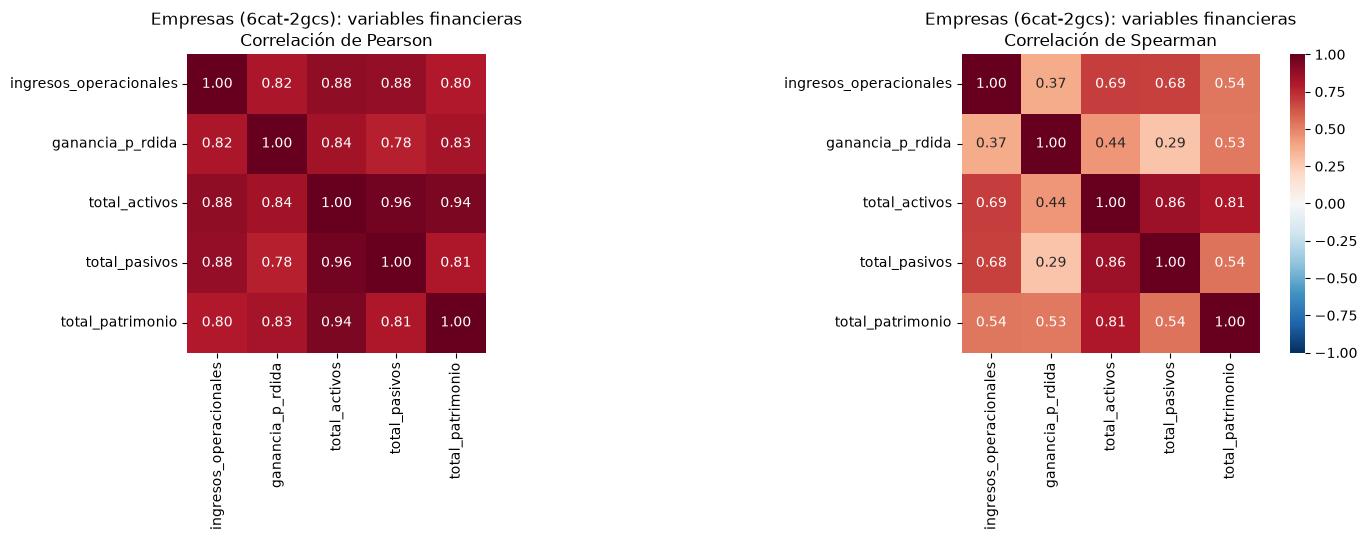

**Pares de variables ordenados por |Spearman|**

pearson  spearman  diferencia (spearman - pearson) fuerza (spearman)
variable_1             variable_2                                                                            
total_activos          total_pasivos       0.963     0.857                           -0.105        muy fuerte
                       total_patrimonio    0.940     0.810                           -0.130        muy fuerte
ingresos_operacionales total_activos       0.884     0.688                           -0.196            fuerte
                       total_pasivos       0.876     0.682                           -0.194            fuerte
total_pasivos          total_patrimonio    0.812     0.542                           -0.270            fuerte
ingresos_operacionales total_patrimonio    0.799     0.537                           -0.262            fuerte
ganancia_p_rdida       total_patrimonio    0.830     0.527                           -0.303            fuerte
                       total_activos       0.840     0.445                           -0.395          moderada
ingresos_operacionales ganancia_p_rdida    0.819     0.374                           -0.445          moderada
ganancia_p_rdida       total_pasivos       0.776     0.286                           -0.491             débil

Entidades vigiladas con quejas: 216


#### Quejas (xyy7-rn7p): indicadores por entidad

**Matriz de covarianza**

,total_quejas,productos_distintos,motivos_distintos,municipios_distintos,meses_con_quejas,%_quejas_ante_SFC,%_quejas_ante_defensor
total_quejas,"139,262,246,310.6529","486,157.4212","2,372,821.2439","32,957,545.7607","592,823.7761","-1,456,626.6349","-99,881.6330"
productos_distintos,"486,157.4212",73.3388,171.9612,"1,072.2597",63.2839,-90.6340,7.8002
motivos_distintos,"2,372,821.2439",171.9612,"1,098.4434","4,754.2031",357.1987,-531.5544,62.2976
municipios_distintos,"32,957,545.7607","1,072.2597","4,754.2031","63,244.4457","2,032.9373","-3,876.4795",95.2725
meses_con_quejas,"592,823.7761",63.2839,357.1987,"2,032.9373",262.9483,-358.3633,32.5740
%_quejas_ante_SFC,"-1,456,626.6349",-90.6340,-531.5544,"-3,876.4795",-358.3633,"1,132.1414",-41.1299
%_quejas_ante_defensor,"-99,881.6330",7.8002,62.2976,95.2725,32.5740,-41.1299,94.7268


**Correlación de Pearson**

,total_quejas,productos_distintos,motivos_distintos,municipios_distintos,meses_con_quejas,%_quejas_ante_SFC,%_quejas_ante_defensor
total_quejas,1.0000,0.1521,0.1918,0.3512,0.0980,-0.1160,-0.0275
productos_distintos,0.1521,1.0000,0.6059,0.4979,0.4557,-0.3145,0.0936
motivos_distintos,0.1918,0.6059,1.0000,0.5704,0.6646,-0.4767,0.1931
municipios_distintos,0.3512,0.4979,0.5704,1.0000,0.4985,-0.4581,0.0389
meses_con_quejas,0.0980,0.4557,0.6646,0.4985,1.0000,-0.6568,0.2064
%_quejas_ante_SFC,-0.1160,-0.3145,-0.4767,-0.4581,-0.6568,1.0000,-0.1256
%_quejas_ante_defensor,-0.0275,0.0936,0.1931,0.0389,0.2064,-0.1256,1.0000


**Correlación de Spearman**

,total_quejas,productos_distintos,motivos_distintos,municipios_distintos,meses_con_quejas,%_quejas_ante_SFC,%_quejas_ante_defensor
total_quejas,1.0000,0.6312,0.8248,0.9548,0.8967,-0.6384,0.3803
productos_distintos,0.6312,1.0000,0.6620,0.6425,0.6189,-0.3069,0.3513
motivos_distintos,0.8248,0.6620,1.0000,0.7990,0.7965,-0.4279,0.4448
municipios_distintos,0.9548,0.6425,0.7990,1.0000,0.8390,-0.5624,0.3595
meses_con_quejas,0.8967,0.6189,0.7965,0.8390,1.0000,-0.5683,0.4102
%_quejas_ante_SFC,-0.6384,-0.3069,-0.4279,-0.5624,-0.5683,1.0000,-0.1635
%_quejas_ante_defensor,0.3803,0.3513,0.4448,0.3595,0.4102,-0.1635,1.0000


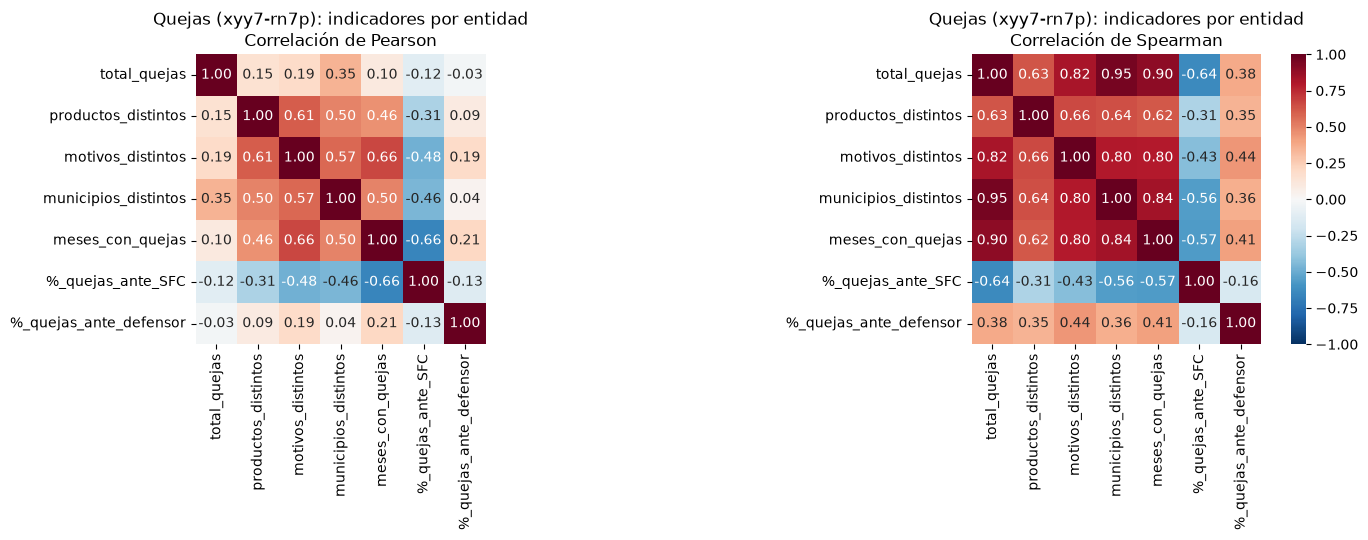

**Pares de variables ordenados por |Spearman|**

pearson  spearman  diferencia (spearman - pearson) fuerza (spearman)
variable_1           variable_2                                                                                  
total_quejas         municipios_distintos      0.351     0.955                            0.604        muy fuerte
                     meses_con_quejas          0.098     0.897                            0.799        muy fuerte
municipios_distintos meses_con_quejas          0.499     0.839                            0.341        muy fuerte
total_quejas         motivos_distintos         0.192     0.825                            0.633        muy fuerte
motivos_distintos    municipios_distintos      0.570     0.799                            0.229        muy fuerte
                     meses_con_quejas          0.665     0.796                            0.132        muy fuerte
productos_distintos  motivos_distintos         0.606     0.662                            0.056            fuerte
                     municipios_distintos      0.498     0.643                            0.145            fuerte
total_quejas         %_quejas_ante_SFC        -0.116    -0.638                           -0.522            fuerte
                     productos_distintos       0.152     0.631                            0.479            fuerte
productos_distintos  meses_con_quejas          0.456     0.619                            0.163            fuerte
meses_con_quejas     %_quejas_ante_SFC        -0.657    -0.568                            0.089            fuerte
municipios_distintos %_quejas_ante_SFC        -0.458    -0.562                           -0.104            fuerte
motivos_distintos    %_quejas_ante_defensor    0.193     0.445                            0.252          moderada
                     %_quejas_ante_SFC        -0.477    -0.428                            0.049          moderada
meses_con_quejas     %_quejas_ante_defensor    0.206     0.410                            0.204          moderada
total_quejas         %_quejas_ante_defensor   -0.027     0.380                            0.408          moderada
municipios_distintos %_quejas_ante_defensor    0.039     0.360                            0.321          moderada
productos_distintos  %_quejas_ante_defensor    0.094     0.351                            0.258          moderada
                     %_quejas_ante_SFC        -0.315    -0.307                            0.008          moderada
%_quejas_ante_SFC    %_quejas_ante_defensor   -0.126    -0.163                           -0.038             débil

#### Cobertura del cruce entidades vigiladas (sr9n-792w) ↔ empresas (6cat-2gcs)

,criterio,entidades_vigiladas_que_cruzan,total_entidades_vigiladas
0,NIT completo,0,456
1,NIT sin dígito de verificación (último dígito),10,456


In [7]:
# ============================================================
# Correlación y covarianza
# ============================================================
entidades = tablas["sr9n-792w"]

def matrices(df: pd.DataFrame, titulo: str) -> pd.DataFrame:
    """Muestra covarianza, Pearson y Spearman; grafica ambas correlaciones y retorna los pares ordenados."""
    datos = df.astype("float64")
    cov = datos.cov()
    pearson = datos.corr(method="pearson")
    spearman = datos.corr(method="spearman")

    display(Markdown(f"#### {titulo}"))
    with pd.option_context("display.width", 250, "display.max_columns", None, "display.float_format", "{:,.4f}".format):
        display(Markdown("**Matriz de covarianza**"));  display(cov)
        display(Markdown("**Correlación de Pearson**")); display(pearson)
        display(Markdown("**Correlación de Spearman**")); display(spearman)

    fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
    for eje, (nombre, m) in zip(ejes, [("Pearson", pearson), ("Spearman", spearman)]):
        sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=eje, cbar=eje is ejes[-1])
        eje.set_title(f"{titulo}\nCorrelación de {nombre}")
    plt.tight_layout(); plt.show()

    # Pares de variables ordenados por la magnitud de la correlación de Spearman
    triangulo = np.triu(np.ones(pearson.shape, dtype=bool), k=1)
    pares = pd.DataFrame({
        "pearson": pearson.where(triangulo).stack(),
        "spearman": spearman.where(triangulo).stack(),
    }).dropna()  # en pandas 3 stack() conserva los NaN: se descartan diagonal y triángulo inferior
    pares["diferencia (spearman - pearson)"] = pares["spearman"] - pares["pearson"]
    pares["fuerza (spearman)"] = pd.cut(pares["spearman"].abs(), [0, 0.3, 0.5, 0.7, 1.0001],
                                        labels=["débil", "moderada", "fuerte", "muy fuerte"], right=False)
    pares = pares.reindex(pares["spearman"].abs().sort_values(ascending=False).index)
    pares.index.names = ["variable_1", "variable_2"]
    with pd.option_context("display.width", 250, "display.float_format", "{:,.3f}".format):
        display(Markdown("**Pares de variables ordenados por |Spearman|**")); display(pares)
    return pares

# --- 1. Variables financieras de las empresas ---
pares_empresas = matrices(empresas[COLS_MONTOS], "Empresas (6cat-2gcs): variables financieras")

# --- 2. Indicadores de quejas agregados por entidad vigilada ---
# Cada fila de quejas es un conteo por entidad, producto, motivo, municipio y mes; se agrega por entidad
q = quejas.assign(
    periodo=quejas["a_o_creacion"] * 100 + quejas["mes_creacion"],  # año-mes, p. ej. 202509
    q_sfc=quejas["cantidad_quejas_recibidas"].where(quejas["instancia_recepcion"] == "Superintendencia Financiera de Colombia", 0),
    q_defensor=quejas["cantidad_quejas_recibidas"].where(quejas["instancia_recepcion"] == "Defensor del consumidor financiero", 0),
)
por_entidad = q.groupby(["tipo_entidad", "codigo_entidad"]).agg(
    total_quejas=("cantidad_quejas_recibidas", "sum"),
    productos_distintos=("producto", "nunique"),
    motivos_distintos=("motivo", "nunique"),
    municipios_distintos=("municipio", "nunique"),
    meses_con_quejas=("periodo", "nunique"),
    q_sfc=("q_sfc", "sum"),
    q_defensor=("q_defensor", "sum"),
)
# Proporción de quejas escaladas a la Superintendencia o al Defensor (posible señal de mala gestión interna)
por_entidad["%_quejas_ante_SFC"] = 100 * por_entidad["q_sfc"] / por_entidad["total_quejas"]
por_entidad["%_quejas_ante_defensor"] = 100 * por_entidad["q_defensor"] / por_entidad["total_quejas"]
por_entidad = por_entidad.drop(columns=["q_sfc", "q_defensor"])
print(f"Entidades vigiladas con quejas: {len(por_entidad)}")
pares_quejas = matrices(por_entidad, "Quejas (xyy7-rn7p): indicadores por entidad")

# --- 3. Viabilidad de cruzar quejas con estados financieros por NIT ---
nits_empresas = set(empresas["nit"].dropna().astype("int64"))
nit_entidades = entidades["numeroidentificacion"].dropna().astype("int64")
cobertura = pd.DataFrame({
    "criterio": ["NIT completo", "NIT sin dígito de verificación (último dígito)"],
    "entidades_vigiladas_que_cruzan": [nit_entidades.isin(nits_empresas).sum(),
                                       (nit_entidades // 10).isin(nits_empresas).sum()],
    "total_entidades_vigiladas": len(nit_entidades),
})
display(Markdown("#### Cobertura del cruce entidades vigiladas (sr9n-792w) ↔ empresas (6cat-2gcs)"))
display(cobertura)


#### Interpretación de correlación y covarianza
- **La covarianza no sirve para comparar pares de variables** porque depende de la escala de cada una (por ejemplo, la covarianza de `total_quejas` con otras variables está en millones y la de los porcentajes en decenas). Por eso la lectura se hace con los coeficientes de correlación, que van de −1 a 1.

**Empresas**
- Activos y pasivos son el par más relacionado (Spearman 0,857) y la ganancia es la variable menos ligada al resto (Spearman de 0,286 con pasivos).
- Pearson da valores mucho más altos que Spearman (por ejemplo, 0,819 contra 0,374 entre ingresos y ganancia). Esa diferencia la producen las pocas empresas muy grandes: **Pearson exagera la relación** y Spearman describe mejor a la mayoría de las empresas.

**Quejas por entidad (216 entidades)**
- Las entidades con más quejas las reciben en más municipios (Spearman 0,955) y durante más meses (0,897): el volumen de quejas refleja sobre todo el tamaño y la presencia territorial de la entidad.
- **A más quejas, menor porcentaje llega a la Superintendencia** (Spearman −0,638, mientras que Pearson da solo −0,116). Las entidades grandes atienden la mayoría de las quejas internamente; en las pequeñas el cliente acude más al regulador.

**Integración**
- Solo 10 de las 456 entidades vigiladas cruzan por NIT con la tabla de empresas, y únicamente si se quita el dígito de verificación (con el NIT completo no cruza ninguna). La tabla de empresas no incluye bancos, así que no es posible correlacionar quejas con estados financieros entidad por entidad.

### Análisis de calidad de los datos
Se evalúan las tres fuentes en seis dimensiones de calidad:

| Dimensión | Qué se verifica |
|---|---|
| **Completitud** | Nulos reales y nulos disfrazados (p. ej. "Pendiente", "0") |
| **Unicidad** | Registros duplicados y llaves repetidas |
| **Validez** | Formatos y rangos (NIT y dígito de verificación, correo, URL, montos, años, meses, conteos) |
| **Consistencia** | Ecuación contable, variantes de escritura de una misma categoría, nombres distintos para un mismo NIT |
| **Integridad referencial** | Que las entidades con quejas existan en el directorio de entidades vigiladas |
| **Oportunidad / cobertura temporal** | Periodos faltantes en las series |

El resultado es un tablero resumen por regla, seguido del detalle de los hallazgos.
*Requiere haber ejecutado las celdas anteriores del punto 4.*

In [8]:
# ============================================================
# Análisis de calidad de los datos (tres fuentes)
# ============================================================
import unicodedata

emp_raw, quejas_q, ent = tablas["6cat-2gcs"], tablas["xyy7-rn7p"], tablas["sr9n-792w"]
reglas = []  # tablero resumen

def registrar(fuente, dimension, regla, problemas, evaluados):
    """Agrega una regla al tablero de calidad. `problemas` es una máscara booleana o un conteo."""
    n_prob = int(problemas.sum()) if hasattr(problemas, "sum") else int(problemas)
    reglas.append({"fuente": fuente, "dimension": dimension, "regla": regla,
                   "evaluados": int(evaluados), "con_problema": n_prob,
                   "% con_problema": round(100 * n_prob / evaluados, 2) if evaluados else np.nan})

def normalizar(s: pd.Series) -> pd.Series:
    """Texto en mayúsculas, sin tildes, sin puntuación y con espacios simples (para comparar categorías)."""
    sin_tildes = s.astype("string").map(
        lambda x: "".join(ch for ch in unicodedata.normalize("NFKD", x) if not unicodedata.combining(ch)) if pd.notna(x) else x)
    return (sin_tildes.str.upper().str.replace(r"[^\w\s]", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True).str.strip())

# --- 1. Completitud: nulos reales y nulos disfrazados ---
PATRON_NULO_DISFRAZADO = r"^(PENDIENTE.*|N/?A|NO APLICA|SIN .*|NINGUN[OA]?|NULL|NONE|-+|\.|0|NO REGISTRA|NO INFORMA)$"
detalle_nulos = []
for fuente, df in tablas.items():
    for col in df.columns:
        texto = df[col].astype("string").str.strip()
        nulos_reales = df[col].isna() | texto.eq("").fillna(False)
        disfrazados = (texto.str.upper().str.match(PATRON_NULO_DISFRAZADO, na=False)
                       | texto.str.lower().str.startswith("pendiente@", na=False))
        if nulos_reales.any() or disfrazados.any():
            detalle_nulos.append({"fuente": fuente, "atributo": col, "nulos_reales": int(nulos_reales.sum()),
                                  "nulos_disfrazados": int(disfrazados.sum()),
                                  "valores_disfrazados": ", ".join(texto[disfrazados].value_counts().index[:3])})
        registrar(fuente, "Completitud", f"{col}: nulo real o disfrazado", nulos_reales | disfrazados, len(df))
detalle_nulos = pd.DataFrame(detalle_nulos)

# --- 2. Unicidad ---
registrar("6cat-2gcs", "Unicidad", "Filas duplicadas exactas", emp_raw.duplicated(), len(emp_raw))
registrar("6cat-2gcs", "Unicidad", "Llave (nit, año de corte) repetida", emp_raw.duplicated(["nit", "a_o_de_corte"]), len(emp_raw))
registrar("xyy7-rn7p", "Unicidad", "Filas duplicadas exactas", quejas_q.duplicated(), len(quejas_q))
registrar("xyy7-rn7p", "Unicidad", "Misma combinación de atributos con distinto conteo",
          quejas_q.duplicated(quejas_q.columns.drop("cantidad_quejas_recibidas")), len(quejas_q))
registrar("sr9n-792w", "Unicidad", "Filas duplicadas exactas", ent.duplicated(), len(ent))
registrar("sr9n-792w", "Unicidad", "Llave (tipo_entidad, cod_entidad) repetida", ent.duplicated(["tipo_entidad", "cod_entidad"]), len(ent))
nit_valido = ent["numeroidentificacion"].fillna(0) != 0
registrar("sr9n-792w", "Unicidad", "NIT repetido entre entidades (excluye NIT = 0)",
          ent.loc[nit_valido, "numeroidentificacion"].duplicated(keep=False), nit_valido.sum())

# --- 3. Validez ---
def digito_verificacion_dian(nit: int) -> int:
    """Dígito de verificación del NIT según el algoritmo de la DIAN (módulo 11)."""
    pesos = [3, 7, 13, 17, 19, 23, 29, 37, 41, 43, 47, 53, 59, 67, 71]
    suma = sum(int(d) * p for d, p in zip(reversed(str(nit)), pesos))
    residuo = suma % 11
    return residuo if residuo in (0, 1) else 11 - residuo

nits_e = emp_raw["nit"].dropna().astype("int64")
registrar("6cat-2gcs", "Validez", "NIT con longitud distinta de 9 dígitos", nits_e.astype(str).str.len().ne(9), len(nits_e))
for col in COLS_MONTOS:
    registrar("6cat-2gcs", "Validez", f"{col}: no convertible a número", a_numero_monetario(emp_raw[col]).isna(), len(emp_raw))
for col in ["total_activos", "total_pasivos", "ingresos_operacionales"]:
    registrar("6cat-2gcs", "Validez", f"{col}: valor negativo", empresas[col] < 0, len(empresas))
registrar("6cat-2gcs", "Validez", "Año de corte fuera de 2000–2026", ~emp_raw["a_o_de_corte"].between(2000, 2026), len(emp_raw))

registrar("xyy7-rn7p", "Validez", "Mes fuera de 1–12", ~quejas_q["mes_creacion"].between(1, 12), len(quejas_q))
registrar("xyy7-rn7p", "Validez", "Año fuera de 2000–2026", ~quejas_q["a_o_creacion"].between(2000, 2026), len(quejas_q))
registrar("xyy7-rn7p", "Validez", "Cantidad de quejas <= 0", quejas_q["cantidad_quejas_recibidas"] <= 0, len(quejas_q))

nits_s = ent.loc[nit_valido, "numeroidentificacion"].astype("int64")
dv_ok = nits_s.map(lambda x: digito_verificacion_dian(x // 10) == x % 10)
registrar("sr9n-792w", "Validez", "NIT con dígito de verificación DIAN inválido (excluye NIT = 0)", ~dv_ok, len(nits_s))
correo = ent["emailprincipal"].astype("string").str.strip()
registrar("sr9n-792w", "Validez", "Correo con formato inválido",
          ~correo.str.match(r"^[\w.+-]+@[\w-]+(\.[\w-]+)+$", na=False), len(ent))
web = ent["uripaginaweb"].astype("string").str.strip()
registrar("sr9n-792w", "Validez", "Página web con formato inválido",
          ~web.str.match(r"^(https?://)?(www\.)?[\w-]+(\.[\w-]+)+(/\S*)?$", na=False), len(ent))

# --- 4. Consistencia ---
# Ecuación contable: activos = pasivos + patrimonio (tolerancia 0,02 por el redondeo a 2 decimales de la fuente)
diferencia_contable = (empresas["total_activos"] - empresas["total_pasivos"] - empresas["total_patrimonio"]).abs()
registrar("6cat-2gcs", "Consistencia", "Activos ≠ pasivos + patrimonio (tolerancia 0,02)", diferencia_contable > 0.02, len(empresas))

# Variantes de escritura: valores distintos que coinciden al normalizar (tildes, puntuación, mayúsculas)
detalle_variantes = []
for fuente, col in [("6cat-2gcs", "departamento_domicilio"), ("6cat-2gcs", "ciudad_domicilio"),
                    ("6cat-2gcs", "raz_n_social"), ("xyy7-rn7p", "departamento"), ("xyy7-rn7p", "municipio"),
                    ("xyy7-rn7p", "motivo"), ("xyy7-rn7p", "producto"), ("sr9n-792w", "ciudad")]:
    original = tablas[fuente][col].dropna().astype("string").str.strip()
    grupos = pd.DataFrame({"original": original, "normalizado": normalizar(original)}).drop_duplicates()
    con_variantes = grupos.groupby("normalizado")["original"].agg(list)
    con_variantes = con_variantes[con_variantes.map(len) > 1]
    registrar(fuente, "Consistencia", f"{col}: valores con varias escrituras",
              len(con_variantes), original.nunique())
    for norm, variantes in con_variantes.head(5).items():
        detalle_variantes.append({"fuente": fuente, "atributo": col, "normalizado": norm, "variantes": " | ".join(variantes)})
detalle_variantes = pd.DataFrame(detalle_variantes)

# Departamentos de 6cat-2gcs que no coinciden con ningún departamento de la fuente de quejas (posibles ciudades o variantes)
deptos_ref = set(normalizar(quejas_q["departamento"].dropna()).unique())
deptos_emp = pd.Series(emp_raw["departamento_domicilio"].dropna().unique())
fuera_catalogo = deptos_emp[~normalizar(deptos_emp).isin(deptos_ref)].sort_values().tolist()
registrar("6cat-2gcs", "Consistencia", "departamento_domicilio fuera del catálogo de departamentos de quejas",
          len(fuera_catalogo), len(deptos_emp))

# Un mismo NIT con varias razones sociales: diferencia de formato vs. cambio real de nombre
nombres = emp_raw[["nit", "raz_n_social"]].dropna().drop_duplicates()
n_nombres = nombres.groupby("nit")["raz_n_social"].nunique()
n_nombres_norm = nombres.assign(norm=normalizar(nombres["raz_n_social"])).groupby("nit")["norm"].nunique()
registrar("6cat-2gcs", "Consistencia", "NIT con más de una razón social (texto original)", n_nombres > 1, len(n_nombres))
registrar("6cat-2gcs", "Consistencia", "NIT con más de una razón social (texto normalizado)", n_nombres_norm > 1, len(n_nombres_norm))

registrar("xyy7-rn7p", "Consistencia", "Municipio informado sin departamento",
          quejas_q["municipio"].notna() & quejas_q["departamento"].isna(), len(quejas_q))

# --- 5. Integridad referencial: entidades con quejas vs. directorio de entidades vigiladas ---
llaves_q = quejas_q[["tipo_entidad", "codigo_entidad"]].drop_duplicates()
llaves_s = ent[["tipo_entidad", "cod_entidad"]].rename(columns={"cod_entidad": "codigo_entidad"})
cruce = llaves_q.merge(llaves_s, how="left", indicator=True)
sin_directorio = cruce[cruce["_merge"] == "left_only"].drop(columns="_merge")
registrar("xyy7-rn7p", "Integridad referencial", "Entidad con quejas ausente del directorio sr9n-792w", len(sin_directorio), len(llaves_q))
filas_huerfanas = quejas_q.merge(sin_directorio, on=["tipo_entidad", "codigo_entidad"])
registrar("xyy7-rn7p", "Integridad referencial", "Quejas (suma) de entidades ausentes del directorio",
          filas_huerfanas["cantidad_quejas_recibidas"].sum(), quejas_q["cantidad_quejas_recibidas"].sum())

# --- 6. Oportunidad / cobertura temporal ---
periodos = quejas_q[["a_o_creacion", "mes_creacion"]].drop_duplicates().astype("int64")
anio_min, anio_max = int(periodos["a_o_creacion"].min()), int(periodos["a_o_creacion"].max())
mes_max = int(periodos.loc[periodos["a_o_creacion"] == anio_max, "mes_creacion"].max())
esperados = pd.period_range(f"{anio_min}-01", f"{anio_max}-{mes_max:02d}", freq="M")
presentes = pd.PeriodIndex([pd.Period(year=a, month=m, freq="M")
                            for a, m in periodos.itertuples(index=False)])
meses_faltantes = esperados.difference(presentes)
registrar("xyy7-rn7p", "Oportunidad", f"Meses sin registros entre {esperados[0]} y {esperados[-1]}", len(meses_faltantes), len(esperados))

# Meses con carga incompleta: total de quejas inferior al 10 % de la mediana mensual
total_por_mes = quejas_q.groupby(["a_o_creacion", "mes_creacion"])["cantidad_quejas_recibidas"].sum()
meses_incompletos = total_por_mes[total_por_mes < 0.10 * total_por_mes.median()]
registrar("xyy7-rn7p", "Oportunidad", "Meses con volumen inferior al 10 % de la mediana mensual (carga incompleta)",
          len(meses_incompletos), len(total_por_mes))

anios_emp = emp_raw.groupby("a_o_de_corte")["nit"].count()
registrar("6cat-2gcs", "Oportunidad", "Años de corte con un número de empresas distinto de 10.000",
          (anios_emp != 10_000).sum(), len(anios_emp))

# --- Resultados ---
tablero = pd.DataFrame(reglas)
resumen_dimension = (tablero.assign(regla_con_hallazgos=tablero["con_problema"] > 0)
                     .groupby(["fuente", "dimension"])
                     .agg(reglas_evaluadas=("regla", "count"), reglas_con_hallazgos=("regla_con_hallazgos", "sum"))
                     .reset_index())

with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 250,
                       "display.max_colwidth", 120, "display.float_format", "{:,.2f}".format):
    display(Markdown("#### Resumen por fuente y dimensión"))
    display(resumen_dimension)
    display(Markdown("#### Tablero de reglas con hallazgos (ordenado por % de registros afectados)"))
    display(tablero[tablero["con_problema"] > 0].sort_values("% con_problema", ascending=False).reset_index(drop=True))
    display(Markdown("#### Reglas sin hallazgos"))
    display(tablero[tablero["con_problema"] == 0][["fuente", "dimension", "regla", "evaluados"]].reset_index(drop=True))
    display(Markdown("#### Detalle: nulos reales y disfrazados por atributo"))
    display(detalle_nulos)
    display(Markdown("#### Detalle: ejemplos de valores con varias escrituras (máx. 5 por atributo)"))
    display(detalle_variantes)
    display(Markdown("#### Detalle: departamentos de 6cat-2gcs fuera del catálogo\n" + ", ".join(fuera_catalogo)))
    display(Markdown("#### Detalle: meses sin registros de quejas\n" + (", ".join(str(m) for m in meses_faltantes) or "ninguno")))
    display(Markdown(f"#### Detalle: meses con carga incompleta (mediana mensual: {total_por_mes.median():,.0f} quejas)"))
    display(meses_incompletos.rename("total_quejas").reset_index())
    display(Markdown("#### Detalle: entidades con quejas ausentes del directorio sr9n-792w"))
    display(filas_huerfanas.groupby(["tipo_entidad", "codigo_entidad"])["cantidad_quejas_recibidas"].sum()
            .sort_values(ascending=False).rename("total_quejas").reset_index())
    display(Markdown("#### Detalle: empresas por año de corte"))
    display(anios_emp.rename("empresas").to_frame().T)


#### Resumen por fuente y dimensión

,fuente,dimension,reglas_evaluadas,reglas_con_hallazgos
0,6cat-2gcs,Completitud,14,0
1,6cat-2gcs,Consistencia,7,6
2,6cat-2gcs,Oportunidad,1,0
3,6cat-2gcs,Unicidad,2,0
4,6cat-2gcs,Validez,10,0
5,sr9n-792w,Completitud,10,7
6,sr9n-792w,Consistencia,1,0
7,sr9n-792w,Unicidad,3,0
8,sr9n-792w,Validez,3,3
9,xyy7-rn7p,Completitud,10,2


#### Tablero de reglas con hallazgos (ordenado por % de registros afectados)

,fuente,dimension,regla,evaluados,con_problema,% con_problema
0,sr9n-792w,Validez,Página web con formato inválido,456,295,64.69
1,sr9n-792w,Completitud,uripaginaweb: nulo real o disfrazado,456,276,60.53
2,6cat-2gcs,Consistencia,NIT con más de una razón social (texto original),15032,3707,24.66
3,6cat-2gcs,Consistencia,NIT con más de una razón social (texto normalizado),15032,3165,21.06
4,sr9n-792w,Completitud,numeroidentificacion: nulo real o disfrazado,456,82,17.98
5,sr9n-792w,Validez,Correo con formato inválido,456,73,16.01
6,6cat-2gcs,Consistencia,ciudad_domicilio: valores con varias escrituras,456,72,15.79
7,6cat-2gcs,Consistencia,departamento_domicilio fuera del catálogo de departamentos de quejas,39,6,15.38
8,sr9n-792w,Completitud,emailprincipal: nulo real o disfrazado,456,51,11.18
9,sr9n-792w,Completitud,representante_legal: nulo real o disfrazado,456,34,7.46


#### Reglas sin hallazgos

,fuente,dimension,regla,evaluados
0,xyy7-rn7p,Completitud,a_o_creacion: nulo real o disfrazado,1400425
1,xyy7-rn7p,Completitud,mes_creacion: nulo real o disfrazado,1400425
2,xyy7-rn7p,Completitud,tipo_entidad: nulo real o disfrazado,1400425
3,xyy7-rn7p,Completitud,codigo_entidad: nulo real o disfrazado,1400425
4,xyy7-rn7p,Completitud,instancia_recepcion: nulo real o disfrazado,1400425
5,xyy7-rn7p,Completitud,motivo: nulo real o disfrazado,1400425
6,xyy7-rn7p,Completitud,producto: nulo real o disfrazado,1400425
7,xyy7-rn7p,Completitud,cantidad_quejas_recibidas: nulo real o disfrazado,1400425
8,sr9n-792w,Completitud,tipo_entidad: nulo real o disfrazado,456
9,sr9n-792w,Completitud,cod_entidad: nulo real o disfrazado,456


... (8 outputs left out)

#### Detalle: entidades con quejas ausentes del directorio sr9n-792w

,tipo_entidad,codigo_entidad,total_quejas
0,127,5,32313
1,127,2,7579
2,13,14,7393
3,127,6,1384
4,10,7,693
5,32,3,599
6,4,125,280
7,127,1,172
8,1,99,22
9,14,10,21


#### Detalle: empresas por año de corte

a_o_de_corte,2021,2022,2023,2024,2025
empresas,10000,10000,10000,10000,10000


#### Interpretación del análisis de calidad
Se evaluaron 75 reglas; 24 tienen hallazgos.

| Fuente | Fortalezas | Problemas principales | Tratamiento (punto 5.1) |
|---|---|---|---|
| **Quejas** (`xyy7-rn7p`) | Sin duplicados; años, meses y conteos válidos. | 5.157 filas (0,37 %) sin departamento ni municipio. 16 de 216 entidades no están en el directorio (0,50 % de las quejas). Febrero de 2026 sin datos y septiembre de 2026 incompleto (5.902 quejas frente a una mediana mensual de 251.799). | Nulos marcados como "SIN INFORMACIÓN"; meses sin datos e incompletos excluidos de promedios y variaciones, sin imputar. |
| **Entidades** (`sr9n-792w`) | Llave `tipo_entidad` + `cod_entidad` completa y única. | "Pendiente" usado como nulo (página web: 60,5 %); 82 NIT en cero (18 %); 73 correos y 295 páginas web con formato inválido; 1 NIT con dígito de verificación inválido. | "Pendiente" y NIT = 0 convertidos a nulos reales; NIT separado del dígito de verificación. |
| **Empresas** (`6cat-2gcs`) | Completa, sin duplicados, valores válidos y exactamente 10.000 empresas por año. | 3.707 NIT (24,7 %) con más de una razón social (3.165 aun después de normalizar el texto); 6 departamentos fuera del catálogo; 72 ciudades con dos escrituras. | Razón social unificada por NIT; departamentos homologados al catálogo de las quejas. |

**Conclusión.** La fuente de quejas tiene la calidad suficiente para medir la reputación, siempre que se excluyan los meses incompletos. El directorio de entidades es confiable para su llave, pero no para sus campos descriptivos. La tabla de empresas requiere homologación antes de cruzarla con las otras fuentes.

## 5. Preparación de los datos
Preparación enfocada en **Banco Davivienda**. El orden de los subpuntos se invierte respecto al enunciado porque las variables derivadas se calculan sobre los datos ya transformados:

- **5.1 Transformaciones realizadas** (limpieza, estandarización, integración).
- **5.2 Variables derivadas** (calculadas a partir de las originales).
- **5.3 Persistencia** de las tablas preparadas en Parquet y SQLite.

*Requiere haber ejecutado las celdas de los puntos 2, 3 y 4.*

### 5.1 Transformaciones realizadas
Se aplican las correcciones identificadas en el análisis de calidad (punto 4) y se construye el universo de análisis: las quejas de los establecimientos bancarios, con Banco Davivienda marcado para compararlo con sus pares.

In [9]:
# ============================================================
# 5.1 Transformaciones realizadas
# ============================================================
import re

bitacora_transformaciones = []
def anotar(paso, tabla, transformacion, antes, despues):
    """Registra cada transformación con una métrica antes/después para dejar trazabilidad."""
    bitacora_transformaciones.append({"paso": paso, "tabla": tabla, "transformación": transformacion,
                                      "antes": antes, "después": despues})

def normalizar_unicos(s: pd.Series) -> pd.Series:
    """Aplica `normalizar` solo sobre los valores distintos (eficiente en tablas grandes)."""
    unicos = pd.Series(s.dropna().unique())
    return s.map(dict(zip(unicos, normalizar(unicos))))

# ---------- T1. Directorio de entidades: nulos disfrazados, NIT y nombre corto ----------
entidades_limpia = entidades_raw.copy()
cols_con_pendiente = ["direccion", "ciudad", "nombrepublicocargo", "representante_legal", "emailprincipal", "uripaginaweb"]
disfrazados_antes = 0
for col in cols_con_pendiente:
    texto = entidades_limpia[col].astype("string").str.strip()
    es_nulo = (texto.str.upper().str.match(PATRON_NULO_DISFRAZADO, na=False)
               | texto.str.lower().str.startswith("pendiente@", na=False))
    disfrazados_antes += int(es_nulo.sum())
    entidades_limpia[col] = texto.mask(es_nulo)
anotar("T1", "entidades", "Valores 'Pendiente' convertidos a nulos reales (6 columnas)",
       f"{disfrazados_antes} nulos disfrazados", f"{int(entidades_limpia[cols_con_pendiente].isna().sum().sum())} nulos reales")

# NIT = 0 pasa a nulo; se separa el NIT base del dígito de verificación (la tabla de empresas usa el NIT sin dígito)
nit_completo = entidades_limpia["numeroidentificacion"].astype("Int64")
nit_completo = nit_completo.mask(nit_completo == 0)
entidades_limpia["nit_base"] = nit_completo // 10
entidades_limpia["digito_verificacion"] = nit_completo % 10
anotar("T1", "entidades", "NIT = 0 convertido a nulo; NIT separado en nit_base y digito_verificacion",
       f"{int((entidades_raw['numeroidentificacion'] == 0).sum())} NIT en 0", f"{int(entidades_limpia['nit_base'].isna().sum())} NIT nulos")

# La razón social trae texto legal ("... podrá girar también con la denominación ..."): se extrae un nombre corto
CORTE_NOMBRE = re.compile(r"\s*(?:,|\(| o | y/o | y podrá| podrá| pudiendo| quien| que | pero| cuya| la cual| es una| igualmente)", re.IGNORECASE)
entidades_limpia["nombre_corto"] = (entidades_limpia["razon_social"].astype("string")
                                    .map(lambda x: CORTE_NOMBRE.split(x)[0].strip().upper()))
anotar("T1", "entidades", "Nombre corto extraído de la razón social",
       f"longitud media {entidades_limpia['razon_social'].str.len().mean():.0f} caracteres",
       f"longitud media {entidades_limpia['nombre_corto'].str.len().mean():.0f} caracteres")

# ---------- T2. Quejas: selección del universo (bancos) y tipos de datos ----------
quejas_bancos = quejas_raw[quejas_raw["tipo_entidad"] == TIPO_BANCO].copy()
anotar("T2", "quejas", "Filtro al universo de análisis: establecimientos bancarios (tipo_entidad = 1)",
       f"{len(quejas_raw):,} filas", f"{len(quejas_bancos):,} filas")

for col in ["a_o_creacion", "mes_creacion", "tipo_entidad", "codigo_entidad", "cantidad_quejas_recibidas"]:
    quejas_bancos[col] = quejas_bancos[col].astype("int64")  # sin nulos: se usa entero nativo
quejas_bancos = quejas_bancos.rename(columns={"a_o_creacion": "anio", "mes_creacion": "mes"})
# Año y mes separados se unifican en una fecha (primer día del mes) para el análisis de series de tiempo
quejas_bancos["fecha"] = pd.to_datetime(pd.DataFrame({"year": quejas_bancos["anio"], "month": quejas_bancos["mes"], "day": 1}))
anotar("T2", "quejas", "Año y mes convertidos en una columna de fecha (primer día del mes)", "2 columnas enteras", "1 columna datetime")

# ---------- T3. Quejas: estandarización de texto y tratamiento de nulos ----------
# Motivos escritos de dos formas (mayúsculas vs. tipo oración): se unifican en la forma que no está toda en mayúsculas
motivos_antes = quejas_bancos["motivo"].nunique()
clave_motivo = normalizar_unicos(quejas_bancos["motivo"])
variantes = (quejas_bancos.assign(clave=clave_motivo)
             .groupby(["clave", "motivo"], as_index=False)["cantidad_quejas_recibidas"].sum())
variantes["en_mayusculas"] = variantes["motivo"].str.isupper()
canonico = (variantes.sort_values(["clave", "en_mayusculas", "cantidad_quejas_recibidas"], ascending=[True, True, False])
            .drop_duplicates("clave").set_index("clave")["motivo"])
quejas_bancos["motivo"] = clave_motivo.map(canonico).astype("string").str.strip()
quejas_bancos["producto"] = quejas_bancos["producto"].astype("string").str.strip()
anotar("T3", "quejas", "Motivos con doble escritura unificados", f"{motivos_antes} motivos distintos", f"{quejas_bancos['motivo'].nunique()} motivos distintos")

# Los nulos de territorio no se eliminan (se perderían quejas): se marcan con una categoría explícita
nulos_territorio = int(quejas_bancos["departamento"].isna().sum())
for col in ["departamento", "municipio"]:
    quejas_bancos[col] = quejas_bancos[col].astype("string").str.strip().fillna("SIN INFORMACIÓN")
anotar("T3", "quejas", "Departamento y municipio nulos reemplazados por 'SIN INFORMACIÓN'",
       f"{nulos_territorio:,} filas con nulo", f"{int(quejas_bancos['departamento'].isna().sum())} filas con nulo")

# ---------- T4. Integración quejas ↔ directorio y marca de Davivienda ----------
bancos = entidades_limpia.loc[entidades_limpia["tipo_entidad"] == TIPO_BANCO, ["cod_entidad", "nombre_corto"]]
quejas_bancos = quejas_bancos.merge(bancos.rename(columns={"cod_entidad": "codigo_entidad", "nombre_corto": "banco"}),
                                    on="codigo_entidad", how="left", validate="many_to_one")
sin_nombre = int(quejas_bancos["banco"].isna().sum())
bancos_con_nombre = quejas_bancos["banco"].nunique()
quejas_bancos["banco"] = quejas_bancos["banco"].fillna("BANCO CÓD. " + quejas_bancos["codigo_entidad"].astype(str) + " (sin directorio)")
quejas_bancos["es_davivienda"] = quejas_bancos["codigo_entidad"] == COD_MARCA
anotar("T4", "quejas", "Integración con el directorio (nombre del banco) y marca es_davivienda",
       "solo códigos de entidad", f"{bancos_con_nombre} bancos con nombre; {sin_nombre:,} filas de un código sin directorio")

quejas_dav = quejas_bancos[quejas_bancos["es_davivienda"]].copy()

# ---------- T5. Calendario completo: meses sin datos y años parciales ----------
meses_esperados = pd.date_range(quejas_bancos["fecha"].min(), quejas_bancos["fecha"].max(), freq="MS")
calendario = pd.DataFrame({"fecha": meses_esperados})
calendario["mes_sin_datos"] = ~calendario["fecha"].isin(quejas_bancos["fecha"].unique())
# Mes con carga incompleta: el total de quejas a bancos es inferior al 10 % de la mediana mensual
total_mes = quejas_bancos.groupby("fecha")["cantidad_quejas_recibidas"].sum().reindex(meses_esperados)
calendario["mes_incompleto"] = (total_mes < 0.10 * total_mes.median()).to_numpy()
calendario["mes_completo"] = ~(calendario["mes_sin_datos"] | calendario["mes_incompleto"])
meses_por_anio = calendario[calendario["mes_completo"]].groupby(calendario["fecha"].dt.year)["fecha"].count()
calendario["anio_parcial"] = calendario["fecha"].dt.year.map(meses_por_anio < 12)
def lista_meses(columna):
    return ", ".join(calendario.loc[calendario[columna], "fecha"].dt.strftime("%Y-%m")) or "ninguno"
anotar("T5", "calendario", "Calendario mensual con marcas de mes sin datos, mes incompleto y año parcial (no se imputa)",
       f"{int((~calendario['mes_sin_datos']).sum())} meses con datos",
       f"{int(calendario['mes_completo'].sum())} meses completos; sin datos: {lista_meses('mes_sin_datos')}; incompletos: {lista_meses('mes_incompleto')}")

# ---------- T6. Datos complementarios (empresas): montos, departamentos y razón social ----------
empresas_limpia = empresas_raw.copy()
for col in COLS_MONTOS:
    empresas_limpia[col] = a_numero_monetario(empresas_limpia[col])
anotar("T6", "empresas", "Montos con '$' convertidos de texto a número (5 columnas)", "dtype string", "dtype float64")

# Departamentos: se corrigen ciudades registradas como departamento y variantes, y se llevan al catálogo de la fuente de quejas
CORRECCION_DEPTO = {"ARMENIA": "QUINDIO", "MONTERIA": "CORDOBA", "VALLEDUPAR": "CESAR", "VALLE": "VALLE DEL CAUCA",
                    "GUAJIRA": "LA GUAJIRA",
                    "SAN ANDRES Y PROVIDENCIA": "ARCHIPIELAGO DE SAN ANDRES PROVIDENCIA Y SANTA CATALINA"}
catalogo_deptos = quejas_raw["departamento"].dropna().drop_duplicates()
catalogo_deptos = dict(zip(normalizar(catalogo_deptos), catalogo_deptos))  # clave normalizada -> nombre oficial
deptos_antes = empresas_limpia["departamento_domicilio"].nunique()
clave_depto = normalizar_unicos(empresas_limpia["departamento_domicilio"]).replace(CORRECCION_DEPTO)
empresas_limpia["departamento"] = clave_depto.map(catalogo_deptos)
anotar("T6", "empresas", "Departamentos corregidos y homologados al catálogo de la fuente de quejas",
       f"{deptos_antes} valores distintos", f"{empresas_limpia['departamento'].nunique()} departamentos; {int(empresas_limpia['departamento'].isna().sum())} sin homologar")

# Un NIT con varias razones sociales: se conserva la del año de corte más reciente
vigente = (empresas_limpia.sort_values("a_o_de_corte").drop_duplicates("nit", keep="last").set_index("nit")["raz_n_social"])
empresas_limpia["razon_social_vigente"] = empresas_limpia["nit"].map(vigente)
anotar("T6", "empresas", "Razón social unificada por NIT (nombre del año más reciente)",
       f"{empresas_limpia['raz_n_social'].nunique():,} nombres", f"{empresas_limpia['razon_social_vigente'].nunique():,} nombres")

# Matriz de la marca: se ubica en el directorio (Grupo Bolívar S.A.) y se cruza por NIT sin dígito de verificación
nit_matriz = entidades_limpia.loc[normalizar(entidades_limpia["razon_social"]) == "GRUPO BOLIVAR S A", "nit_base"]
assert len(nit_matriz) == 1
grupo_bolivar = (empresas_limpia[empresas_limpia["nit"] == nit_matriz.iloc[0]]
                 .sort_values("a_o_de_corte")[["a_o_de_corte", "razon_social_vigente"] + COLS_MONTOS].reset_index(drop=True))
anotar("T6", "empresas", "Extracción de la matriz de la marca (Grupo Bolívar S.A.) por NIT",
       f"{len(empresas_limpia):,} filas", f"{len(grupo_bolivar)} filas (años {grupo_bolivar['a_o_de_corte'].min()}–{grupo_bolivar['a_o_de_corte'].max()})")

# ---------- Resultados ----------
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 250, "display.max_colwidth", 110):
    display(Markdown("#### Bitácora de transformaciones"))
    display(pd.DataFrame(bitacora_transformaciones))
    display(Markdown(f"#### Quejas de Banco Davivienda ya transformadas: {len(quejas_dav):,} filas, "
                     f"{quejas_dav['cantidad_quejas_recibidas'].sum():,} quejas"))
    display(quejas_dav.head())
    display(Markdown("#### Bancos del universo de análisis (nombre corto)"))
    display(quejas_bancos.groupby(["codigo_entidad", "banco"])["cantidad_quejas_recibidas"].sum()
            .sort_values(ascending=False).rename("total_quejas").reset_index())
    display(Markdown("#### Calendario: meses sin datos y años parciales"))
    display(calendario.groupby(calendario["fecha"].dt.year).agg(meses=("fecha", "count"), meses_sin_datos=("mes_sin_datos", "sum"),
                                                                meses_incompletos=("mes_incompleto", "sum"),
                                                                meses_completos=("mes_completo", "sum"),
                                                                anio_parcial=("anio_parcial", "first")))
    display(Markdown("#### Quejas a bancos en los últimos 4 meses (evidencia del mes incompleto)"))
    display(total_mes.tail(4).rename("quejas_bancos").rename_axis("fecha").reset_index())
    display(Markdown("#### Matriz de la marca en los datos complementarios (Grupo Bolívar S.A.)"))
    display(grupo_bolivar)

#### Bitácora de transformaciones

,paso,tabla,transformación,antes,después
0,T1,entidades,Valores 'Pendiente' convertidos a nulos reales (6 columnas),421 nulos disfrazados,421 nulos reales
1,T1,entidades,NIT = 0 convertido a nulo; NIT separado en nit_base y digito_verificacion,82 NIT en 0,82 NIT nulos
2,T1,entidades,Nombre corto extraído de la razón social,longitud media 68 caracteres,longitud media 38 caracteres
3,T2,quejas,Filtro al universo de análisis: establecimientos bancarios (tipo_entidad = 1),"1,400,425 filas","801,444 filas"
4,T2,quejas,Año y mes convertidos en una columna de fecha (primer día del mes),2 columnas enteras,1 columna datetime
5,T3,quejas,Motivos con doble escritura unificados,167 motivos distintos,163 motivos distintos
6,T3,quejas,Departamento y municipio nulos reemplazados por 'SIN INFORMACIÓN',"4,015 filas con nulo",0 filas con nulo
7,T4,quejas,Integración con el directorio (nombre del banco) y marca es_davivienda,solo códigos de entidad,30 bancos con nombre; 21 filas de un código sin directorio
8,T5,calendario,"Calendario mensual con marcas de mes sin datos, mes incompleto y año parcial (no se imputa)",44 meses con datos,43 meses completos; sin datos: 2026-02; incompletos: 2026-09
9,T6,empresas,Montos con '$' convertidos de texto a número (5 columnas),dtype string,dtype float64


#### Quejas de Banco Davivienda ya transformadas: 105,822 filas, 1,198,279 quejas

,anio,mes,tipo_entidad,codigo_entidad,instancia_recepcion,motivo,producto,departamento,municipio,cantidad_quejas_recibidas,fecha,banco,es_davivienda
1,2025,11,1,39,Entidad vigilada,Inconsistencias en el movimiento y saldo total del producto,Cuenta de ahorro,META,VILLAVICENCIO,1,2025-11-01,BANCO DAVIVIENDA S.A.,True
3,2025,11,1,39,Entidad vigilada,No disponibilidad o fallas de los canales de atención,Otros productos de Establecimientos de Crédito y SEDPE,HUILA,PITALITO,1,2025-11-01,BANCO DAVIVIENDA S.A.,True
21,2025,11,1,39,Entidad vigilada,Información o asesoría incompleta y/o errada,Otros productos de Establecimientos de Crédito y SEDPE,CUNDINAMARCA,MADRID,1,2025-11-01,BANCO DAVIVIENDA S.A.,True
27,2025,11,1,39,Entidad vigilada,No disponibilidad o fallas de los canales de atención,Cuenta de ahorro,CASANARE,MONTERREY,1,2025-11-01,BANCO DAVIVIENDA S.A.,True
29,2025,11,1,39,Entidad vigilada,Inconsistencias en el movimiento y saldo total del producto,Otros productos de Establecimientos de Crédito y SEDPE,NARIÑO,PASTO,1,2025-11-01,BANCO DAVIVIENDA S.A.,True


#### Bancos del universo de análisis (nombre corto)

,codigo_entidad,banco,total_quejas
0,7,BANCOLOMBIA S.A.,5334234
1,39,BANCO DAVIVIENDA S.A.,1198279
2,13,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S.A.,370392
3,42,LAMBDA BANK S.A.,347156
4,1,BANCO DE BOGOTÁ S.A.,243350
5,2,BANCO POPULAR S.A.,136880
6,56,BANCO FALABELLA S.A.,135483
7,43,BANCO AGRARIO DE COLOMBIA S.A.,119285
8,23,BANCO DE OCCIDENTE,110956
9,30,BANCO CAJA SOCIAL S.A.,92692


... (2 outputs left out)

#### Quejas a bancos en los últimos 4 meses (evidencia del mes incompleto)

,fecha,quejas_bancos
0,2026-06-01,212249.0
1,2026-07-01,239116.0
2,2026-08-01,218320.0
3,2026-09-01,3884.0


#### Matriz de la marca en los datos complementarios (Grupo Bolívar S.A.)

,a_o_de_corte,razon_social_vigente,ingresos_operacionales,ganancia_p_rdida,total_activos,total_pasivos,total_patrimonio
0,2021,GRUPO BOLIVAR S. A.,1.02,0.97,13.8,1.61,12.19
1,2022,GRUPO BOLIVAR S. A.,1.39,1.18,14.91,1.76,13.14
2,2023,GRUPO BOLIVAR S. A.,1.09,1.49,16.22,2.11,14.11
3,2024,GRUPO BOLIVAR S. A.,1.58,1.8,16.64,1.68,14.95
4,2025,GRUPO BOLIVAR S. A.,0.94,0.88,15.96,1.39,14.56


#### Análisis y justificación de las transformaciones

| Paso | Qué se hizo | Por qué |
|---|---|---|
| **T1** | En el directorio de entidades, 421 valores "Pendiente" y 82 NIT en cero se convirtieron en nulos reales; el NIT se separó en base y dígito de verificación; se extrajo un nombre corto de cada entidad. | Un "Pendiente" cuenta como dato válido y oculta la falta de información. El NIT sin dígito es la llave para cruzar con la tabla de empresas. La razón social original incluye texto legal (68 caracteres en promedio) que no sirve para tablas ni gráficos. |
| **T2** | Las quejas se filtraron a los establecimientos bancarios: de 1.400.425 a 801.444 filas. Año y mes se unieron en una fecha. | Comparar a Davivienda con aseguradoras o fondos de pensiones no es justo: tienen productos y volúmenes distintos. Sus pares son los demás bancos. La fecha única permite ordenar y calcular variaciones en el tiempo. |
| **T3** | Se unificaron los motivos escritos de dos formas (de 167 a 163) y los 4.015 registros sin departamento ni municipio se marcaron como "SIN INFORMACIÓN". | Un mismo motivo escrito en mayúsculas y en minúsculas se contaría como dos. Los nulos de territorio no se eliminan porque son quejas reales: borrarlos subestimaría el total. |
| **T4** | Las quejas se unieron con el directorio para traer el nombre del banco y se marcó a Davivienda. | Sin esta integración las quejas solo tienen códigos. Quedaron 30 bancos con nombre y un código (99) sin directorio, con apenas 21 filas, que se conserva identificado como tal. |
| **T5** | Se construyó un calendario mensual completo. Febrero de 2026 no tiene datos y septiembre de 2026 está incompleto (3.884 quejas a bancos frente a más de 200.000 en un mes normal). | No se imputan valores: inventar un mes alteraría la tendencia. Los dos meses se marcan para excluirlos de promedios y variaciones. Quedan 43 meses completos, 7 de ellos en 2026. |
| **T6** | En los datos complementarios, los montos pasaron de texto con "$" a número, los departamentos se homologaron al catálogo de la fuente de quejas (de 39 valores a 33 departamentos, sin pendientes) y la razón social se unificó por NIT (de 19.414 a 15.024 nombres). Se extrajo a Grupo Bolívar S.A. (2021 a 2025). | Sin convertir los montos no se puede calcular nada. Sin homologar los departamentos no se puede cruzar con las quejas. Un NIT debe tener un solo nombre para no contar la misma empresa varias veces. |

**Resultado.** El universo de análisis queda en 801.444 registros de 31 bancos, de los cuales 105.822 (1.198.279 quejas) son de Banco Davivienda.

**Hallazgo nuevo de calidad.** El mes incompleto de septiembre de 2026 no se había detectado en el punto 4, porque allí solo se verificó que cada mes tuviera registros, no que su volumen fuera normal.

### 5.2 Identificación de nuevas variables derivadas
A partir de las variables originales se calculan indicadores que permiten responder las preguntas del proyecto: evolución y posición relativa de Davivienda frente a los demás bancos, composición de sus quejas y distribución territorial.

In [10]:
# ============================================================
# 5.2 Variables derivadas (calculadas)
# ============================================================
diccionario = []
def derivada(variable, tabla, formula, justificacion):
    diccionario.append({"variable": variable, "tabla": tabla, "cálculo": formula, "para qué sirve": justificacion})

# ---------- D1. Variables a nivel de registro (quejas_bancos) ----------
def clasificar(texto_normalizado: pd.Series, reglas: list, por_defecto: str) -> pd.Series:
    """Asigna la primera categoría cuyo patrón aparece en el texto normalizado."""
    unicos = pd.Series(texto_normalizado.dropna().unique())
    def categoria(x):
        return next((cat for cat, patron in reglas if re.search(patron, x)), por_defecto)
    return texto_normalizado.map(dict(zip(unicos, unicos.map(categoria))))

REGLAS_PRODUCTO = [
    ("Otros productos", r"^OTROS PRODUCTOS"),  # va primero: "Establecimientos de Crédito" no es un crédito
    ("Tarjetas de crédito", r"TARJETA"),
    ("Depósitos de bajo monto y ordinarios", r"DEPOSITO"),
    ("Cuentas de ahorro y corriente", r"CUENTA"),
    ("Créditos y leasing", r"CREDITO|LEASING|LIBRANZA"),
    ("Inversión y ahorro a plazo", r"CDT|FONDO|FIC|INVERSION"),
]
REGLAS_MOTIVO = [
    ("Fraude y seguridad", r"NO RECONOCIDA|SUPLANTACION|FRAUDE|HURTO|SEGURIDAD"),
    ("Canales y disponibilidad", r"CANAL|DISPONIBILIDAD|CAJERO|OFICINA"),
    ("Reportes y datos personales", r"CENTRALES|HABEAS|DATOS PERSONALES"),
    ("Cobros, tasas y liquidación", r"TASA|COBRO|COBRANZA|EMBARGO|COMISION|LIQUIDACION|CUOTA DE MANEJO|INTERES|HONORARIOS"),
    ("Errores operativos", r"MAL APLICAD|ERROR|INCONSISTENCIA|DEMORA|INCUMPLIMIENTO|NO ABONO|FALLA"),
    ("Atención e información", r"TRATO|INFORMACION|PUBLICIDAD|ASESOR|ATENCION|RESPUESTA|DIFERENCIA DEL PRODUCTO|EXTRACTOS"),
]
quejas_bancos["familia_producto"] = clasificar(normalizar_unicos(quejas_bancos["producto"]), REGLAS_PRODUCTO, "Otros productos")
quejas_bancos["categoria_motivo"] = clasificar(normalizar_unicos(quejas_bancos["motivo"]), REGLAS_MOTIVO, "Otros motivos")
quejas_bancos["trimestre"] = quejas_bancos["fecha"].dt.to_period("Q").astype(str)
quejas_bancos["queja_escalada"] = quejas_bancos["instancia_recepcion"] != "Entidad vigilada"
quejas_bancos["log_cantidad"] = np.log1p(quejas_bancos["cantidad_quejas_recibidas"])
quejas_dav = quejas_bancos[quejas_bancos["es_davivienda"]].copy()

derivada("familia_producto", "quejas_bancos", "Agrupación de `producto` por palabras clave", "Reducir los productos a pocas familias comparables")
derivada("categoria_motivo", "quejas_bancos", "Agrupación de `motivo` por palabras clave", "Resumir los motivos en causas de insatisfacción accionables")
derivada("trimestre", "quejas_bancos", "Trimestre calendario de `fecha`", "Suavizar la serie mensual y comparar periodos")
derivada("queja_escalada", "quejas_bancos", "`instancia_recepcion` distinta de 'Entidad vigilada'", "Identificar quejas que salen del banco hacia el Defensor o la Superintendencia")
derivada("log_cantidad", "quejas_bancos", "log(1 + `cantidad_quejas_recibidas`)", "Reducir el sesgo positivo detectado en el punto 4")

# ---------- D2. Panel mensual de Davivienda frente a los bancos ----------
VALOR = "cantidad_quejas_recibidas"
fechas = pd.DatetimeIndex(calendario["fecha"])
por_banco = quejas_bancos.pivot_table(index="fecha", columns="codigo_entidad", values=VALOR, aggfunc="sum", fill_value=0).reindex(fechas)

dav_mensual = pd.DataFrame(index=fechas)
dav_mensual.index.name = "fecha"
dav_mensual["quejas_davivienda"] = por_banco[COD_MARCA]
dav_mensual["quejas_bancos"] = por_banco.sum(axis=1, min_count=1)
dav_mensual["quejas_otros_bancos"] = dav_mensual["quejas_bancos"] - dav_mensual["quejas_davivienda"]
dav_mensual["participacion_%"] = 100 * dav_mensual["quejas_davivienda"] / dav_mensual["quejas_bancos"]
dav_mensual["ranking_entre_bancos"] = por_banco.rank(axis=1, ascending=False, method="min")[COD_MARCA]
# Las variables de dinámica se calculan solo con meses completos (el mes incompleto generaría caídas ficticias)
mes_completo = calendario["mes_completo"].to_numpy()
serie_dav = dav_mensual["quejas_davivienda"].where(mes_completo)
serie_otros = dav_mensual["quejas_otros_bancos"].where(mes_completo)
dav_mensual["variacion_mensual_%"] = 100 * serie_dav.pct_change(fill_method=None)
dav_mensual["variacion_interanual_%"] = 100 * serie_dav.pct_change(12, fill_method=None)
dav_mensual["media_movil_3m"] = serie_dav.rolling(3, min_periods=3).mean()
# Índices con base 100 en el primer mes: comparan el ritmo de crecimiento de Davivienda con el del resto
dav_mensual["indice_davivienda"] = 100 * serie_dav / serie_dav.iloc[0]
dav_mensual["indice_otros_bancos"] = 100 * serie_otros / serie_otros.iloc[0]

def participacion_mensual(columna, valor):
    """% de las quejas mensuales de Davivienda que corresponden a `valor` en `columna`."""
    t = quejas_dav.pivot_table(index="fecha", columns=columna, values=VALOR, aggfunc="sum", fill_value=0).reindex(fechas)
    return 100 * t[valor] / t.sum(axis=1, min_count=1)

dav_mensual["%_ante_SFC"] = participacion_mensual("instancia_recepcion", "Superintendencia Financiera de Colombia")
dav_mensual["%_ante_defensor"] = participacion_mensual("instancia_recepcion", "Defensor del consumidor financiero")
dav_mensual["%_fraude_y_seguridad"] = participacion_mensual("categoria_motivo", "Fraude y seguridad")
# Concentración por producto: índice Herfindahl-Hirschman (0 = disperso, 10.000 = un solo producto)
prod_mes = quejas_dav.pivot_table(index="fecha", columns="producto", values=VALOR, aggfunc="sum", fill_value=0).reindex(fechas)
dav_mensual["hhi_producto"] = ((100 * prod_mes.div(prod_mes.sum(axis=1, min_count=1), axis=0)) ** 2).sum(axis=1, min_count=1)
dav_mensual = dav_mensual.join(calendario.set_index("fecha")[["mes_sin_datos", "mes_incompleto", "mes_completo", "anio_parcial"]]).reset_index()

# Serie mensual de todos los bancos en formato largo (para comparar a Davivienda con sus pares)
nombres_banco = quejas_bancos.drop_duplicates("codigo_entidad").set_index("codigo_entidad")["banco"]
bancos_mensual = (por_banco.rename_axis("fecha").reset_index().melt(id_vars="fecha", var_name="codigo_entidad", value_name="quejas")
                  .dropna(subset="quejas"))
bancos_mensual["banco"] = bancos_mensual["codigo_entidad"].map(nombres_banco)
bancos_mensual["participacion_%"] = 100 * bancos_mensual["quejas"] / bancos_mensual.groupby("fecha")["quejas"].transform("sum")
bancos_mensual["es_davivienda"] = bancos_mensual["codigo_entidad"] == COD_MARCA

derivada("participacion_%", "dav_mensual", "quejas de Davivienda / quejas de todos los bancos × 100", "Medir la posición relativa de la marca, aislando el crecimiento general del sistema")
derivada("ranking_entre_bancos", "dav_mensual", "Posición de Davivienda al ordenar los bancos por quejas del mes", "Seguimiento simple de la posición frente a los pares")
derivada("variacion_mensual_% / variacion_interanual_%", "dav_mensual", "Cambio % frente al mes anterior / al mismo mes del año anterior", "Detectar picos (posibles crisis) y tendencia sin estacionalidad")
derivada("bancos_mensual (tabla)", "bancos_mensual", "Quejas y participación % de cada banco por mes (formato largo)", "Comparar la serie de Davivienda con la de cada banco par")
derivada("media_movil_3m", "dav_mensual", "Promedio de los últimos 3 meses completos", "Suavizar la serie para ver la tendencia")
derivada("indice_davivienda / indice_otros_bancos", "dav_mensual", "Quejas del mes / quejas del primer mes × 100", "Comparar el ritmo de crecimiento con el resto de bancos")
derivada("%_ante_SFC / %_ante_defensor", "dav_mensual", "Quejas radicadas ante la SFC o el Defensor / total × 100", "Aproximar la insatisfacción con la respuesta directa del banco")
derivada("%_fraude_y_seguridad", "dav_mensual", "Quejas de la categoría 'Fraude y seguridad' / total × 100", "Seguir la principal causa de queja")
derivada("hhi_producto", "dav_mensual", "Suma de los cuadrados de la participación % de cada producto", "Saber si las quejas se concentran en pocos productos")

# ---------- D3. Composición: Davivienda frente a los demás bancos ----------
def composicion(columna):
    """Participación % de cada categoría en Davivienda y en los demás bancos, y su diferencia en puntos porcentuales."""
    t = quejas_bancos.pivot_table(index=columna, columns="es_davivienda", values=VALOR, aggfunc="sum", fill_value=0)
    t = t.rename(columns={True: "quejas_davivienda", False: "quejas_otros_bancos"})[["quejas_davivienda", "quejas_otros_bancos"]]
    t["%_davivienda"] = 100 * t["quejas_davivienda"] / t["quejas_davivienda"].sum()
    t["%_otros_bancos"] = 100 * t["quejas_otros_bancos"] / t["quejas_otros_bancos"].sum()
    t["diferencia_pp"] = t["%_davivienda"] - t["%_otros_bancos"]
    # Índice de especialización: > 1 indica que la categoría pesa más en Davivienda que en los demás bancos
    t["indice_especializacion"] = t["%_davivienda"] / t["%_otros_bancos"]
    return t.sort_values("quejas_davivienda", ascending=False).reset_index()

dav_familia = composicion("familia_producto")
dav_motivo = composicion("categoria_motivo")
dav_instancia = composicion("instancia_recepcion")
dav_departamento = composicion("departamento")
derivada("diferencia_pp / indice_especializacion", "dav_familia, dav_motivo, dav_instancia, dav_departamento",
         "% de la categoría en Davivienda − (o ÷) % en los demás bancos", "Distinguir problemas propios de la marca de los que son comunes a todo el sector")

# Contexto empresarial del departamento (datos complementarios, último año de corte)
ultimo_corte = int(empresas_limpia["a_o_de_corte"].max())
contexto = (empresas_limpia[empresas_limpia["a_o_de_corte"] == ultimo_corte].groupby("departamento")
            .agg(grandes_empresas=("nit", "nunique"), ingresos_grandes_empresas=("ingresos_operacionales", "sum")).reset_index())
dav_departamento = dav_departamento.merge(contexto, on="departamento", how="left")
dav_departamento["quejas_por_gran_empresa"] = dav_departamento["quejas_davivienda"] / dav_departamento["grandes_empresas"]
derivada("grandes_empresas / quejas_por_gran_empresa", "dav_departamento",
         f"N.º de grandes empresas del departamento ({ultimo_corte}) y quejas de Davivienda por cada una", "Relacionar las quejas con el tamaño económico del territorio")

# ---------- D4. Resumen anual con los datos de la matriz ----------
completos = dav_mensual[dav_mensual["mes_completo"]]
dav_anual = (completos.groupby(completos["fecha"].dt.year)
             .agg(quejas_davivienda=("quejas_davivienda", "sum"), quejas_bancos=("quejas_bancos", "sum"),
                  meses_completos=("mes_completo", "sum")).rename_axis("anio").reset_index())
dav_anual["participacion_%"] = 100 * dav_anual["quejas_davivienda"] / dav_anual["quejas_bancos"]
dav_anual["promedio_mensual"] = dav_anual["quejas_davivienda"] / dav_anual["meses_completos"]
dav_anual["variacion_promedio_mensual_%"] = 100 * dav_anual["promedio_mensual"].pct_change()
dav_anual = dav_anual.merge(grupo_bolivar.rename(columns={"a_o_de_corte": "anio"})[["anio", "ingresos_operacionales", "ganancia_p_rdida", "total_activos"]]
                            .add_suffix("_matriz").rename(columns={"anio_matriz": "anio"}), on="anio", how="left")
derivada("promedio_mensual / variacion_promedio_mensual_%", "dav_anual", "Quejas del año en meses completos / n.º de meses completos, y su cambio % anual",
         "Comparar años completos con el año parcial (2026) sin distorsión")
derivada("*_matriz", "dav_anual", "Ingresos, ganancia y activos de Grupo Bolívar S.A. del mismo año", "Dar contexto financiero de la matriz a la evolución de las quejas")

# ---------- Resultados ----------
total_dav, total_bancos = quejas_dav[VALOR].sum(), quejas_bancos[VALOR].sum()
ranking_total = quejas_bancos.groupby("banco")[VALOR].sum().rank(ascending=False, method="min")
print(f"Quejas de Banco Davivienda: {total_dav:,} de {total_bancos:,} quejas a bancos ({100 * total_dav / total_bancos:.2f} %)")
print(f"Posición entre los {quejas_bancos['banco'].nunique()} bancos por total de quejas: {int(ranking_total[quejas_dav['banco'].iloc[0]])}")
print(f"Motivos de Davivienda clasificados como 'Otros motivos': "
      f"{100 * quejas_dav.loc[quejas_dav['categoria_motivo'] == 'Otros motivos', VALOR].sum() / total_dav:.2f} % de sus quejas")

with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 250,
                       "display.max_colwidth", 90, "display.float_format", "{:,.2f}".format):
    display(Markdown("#### Diccionario de variables derivadas")); display(pd.DataFrame(diccionario))
    display(Markdown("#### Resumen anual (`dav_anual`)")); display(dav_anual)
    display(Markdown("#### Panel mensual (`dav_mensual`)")); display(dav_mensual.drop(columns=["quejas_otros_bancos", "mes_completo"]))
    display(Markdown("#### Composición por familia de producto (`dav_familia`)")); display(dav_familia)
    display(Markdown("#### Composición por categoría de motivo (`dav_motivo`)")); display(dav_motivo)
    display(Markdown("#### Composición por instancia de recepción (`dav_instancia`)")); display(dav_instancia)
    display(Markdown("#### Departamentos con más quejas de Davivienda (`dav_departamento`, 10 primeros)")); display(dav_departamento.head(10))
    display(Markdown("#### Motivos de Davivienda en la categoría 'Otros motivos' (10 principales, para validar las reglas)"))
    display(quejas_dav[quejas_dav["categoria_motivo"] == "Otros motivos"].groupby("motivo")[VALOR].sum().nlargest(10).reset_index())

Quejas de Banco Davivienda: 1,198,279 de 8,513,837 quejas a bancos (14.07 %)
Posición entre los 31 bancos por total de quejas: 2
Motivos de Davivienda clasificados como 'Otros motivos': 2.12 % de sus quejas


#### Diccionario de variables derivadas

,variable,tabla,cálculo,para qué sirve
0,familia_producto,quejas_bancos,Agrupación de `producto` por palabras clave,Reducir los productos a pocas familias comparables
1,categoria_motivo,quejas_bancos,Agrupación de `motivo` por palabras clave,Resumir los motivos en causas de insatisfacción accionables
2,trimestre,quejas_bancos,Trimestre calendario de `fecha`,Suavizar la serie mensual y comparar periodos
3,queja_escalada,quejas_bancos,`instancia_recepcion` distinta de 'Entidad vigilada',Identificar quejas que salen del banco hacia el Defensor o la Superintendencia
4,log_cantidad,quejas_bancos,log(1 + `cantidad_quejas_recibidas`),Reducir el sesgo positivo detectado en el punto 4
5,participacion_%,dav_mensual,quejas de Davivienda / quejas de todos los bancos × 100,"Medir la posición relativa de la marca, aislando el crecimiento general del sistema"
6,ranking_entre_bancos,dav_mensual,Posición de Davivienda al ordenar los bancos por quejas del mes,Seguimiento simple de la posición frente a los pares
7,variacion_mensual_% / variacion_interanual_%,dav_mensual,Cambio % frente al mes anterior / al mismo mes del año anterior,Detectar picos (posibles crisis) y tendencia sin estacionalidad
8,bancos_mensual (tabla),bancos_mensual,Quejas y participación % de cada banco por mes (formato largo),Comparar la serie de Davivienda con la de cada banco par
9,media_movil_3m,dav_mensual,Promedio de los últimos 3 meses completos,Suavizar la serie para ver la tendencia


#### Resumen anual (`dav_anual`)

,anio,quejas_davivienda,quejas_bancos,meses_completos,participacion_%,promedio_mensual,variacion_promedio_mensual_%,ingresos_operacionales_matriz,ganancia_p_rdida_matriz,total_activos_matriz
0,2023,"274,088.00","1,508,243.00",12,18.17,"22,840.67",NaN,1.09,1.49,16.22
1,2024,"343,076.00","2,666,499.00",12,12.87,"28,589.67",25.17,1.58,1.80,16.64
2,2025,"345,351.00","2,761,458.00",12,12.51,"28,779.25",0.66,0.94,0.88,15.96
3,2026,"234,914.00","1,573,753.00",7,14.93,"33,559.14",16.61,<NA>,<NA>,<NA>


#### Panel mensual (`dav_mensual`)

... (7 outputs left out)

#### Departamentos con más quejas de Davivienda (`dav_departamento`, 10 primeros)

,departamento,quejas_davivienda,quejas_otros_bancos,%_davivienda,%_otros_bancos,diferencia_pp,indice_especializacion,grandes_empresas,ingresos_grandes_empresas,quejas_por_gran_empresa
0,"BOGOTÁ, D.C.",765973,2020154,63.92,27.61,36.31,2.31,"4,002.00",955.61,191.40
1,ANTIOQUIA,103987,3713406,8.68,50.76,-42.08,0.17,"1,876.00",318.65,55.43
2,VALLE DEL CAUCA,49975,258111,4.17,3.53,0.64,1.18,858.00,129.44,58.25
3,CUNDINAMARCA,37240,146113,3.11,2.00,1.11,1.56,805.00,90.31,46.26
4,ATLÁNTICO,36316,202696,3.03,2.77,0.26,1.09,489.00,103.85,74.27
5,SANTANDER,22968,123788,1.92,1.69,0.22,1.13,344.00,39.08,66.77
6,BOLÍVAR,19051,103952,1.59,1.42,0.17,1.12,223.00,65.66,85.43
7,RISARALDA,18262,45333,1.52,0.62,0.90,2.46,185.00,24.27,98.71
8,SIN INFORMACIÓN,16901,4881,1.41,0.07,1.34,21.14,NaN,<NA>,NaN
9,CALDAS,15613,34665,1.30,0.47,0.83,2.75,116.00,19.17,134.59


#### Motivos de Davivienda en la categoría 'Otros motivos' (10 principales, para validar las reglas)

,motivo,cantidad_quejas_recibidas
0,Otros motivos,23843
1,Inconformidad por bloqueo de productos,895
2,Inconvenientes con la dación en pago,237
3,Inconformidad con procesos internos de conocimiento del cliente y SARLAFT,174
4,"Inconformidad en procesos - Constitución, Modificación y Levantamiento - de garantía",134
5,OTROS,72
6,Vinculación no autorizada,26
7,No cancelación o terminación de los productos,18
8,DIFICULTAD EN COMUNICACIÓN CON LA ENTIDAD,10
9,Dificultad en la comunicación con la entidad,9


#### Análisis y justificación de las variables derivadas

**Por qué se necesitan.** Las variables originales solo dicen cuántas quejas hubo por combinación de entidad, producto, motivo, lugar y mes. Para hablar de reputación hacen falta medidas relativas (frente al sector y frente al pasado) y categorías más amplias que los 163 motivos y las decenas de productos.

**1. Evolución y posición frente al sector (pregunta 1)**
- Davivienda ocupa el puesto 2 entre los 31 bancos en todos los meses del periodo.
- El promedio mensual de quejas subió 25,2 % en 2024, se estabilizó en 2025 (+0,7 %) y vuelve a subir en 2026 (+16,6 %, con 7 meses completos).
- En todos los meses completos de 2026 la variación interanual es positiva, entre +12 % y +27 %.
- La participación bajó de 18,2 % (2023) a 12,5 % (2025) y repunta a 14,9 % en 2026. La variable `participacion_%` es clave porque separa el crecimiento propio del crecimiento general del sector.

**2. Causas de la insatisfacción (pregunta 2)**
- **Fraude y seguridad** es la categoría dominante: 55,6 % de las quejas de Davivienda frente a 29,8 % en los demás bancos (índice de especialización 1,87). Su peso mensual pasó de 31,8 % en enero de 2023 a entre 62 % y 69 % en los meses completos desde marzo de 2026.
- **Tarjetas de crédito** pesa casi el doble que en los demás bancos (32,8 % frente a 16,8 %).
- "Otros productos de establecimientos de crédito" pesa 14,1 % en Davivienda y 2,5 % en los demás. Es una categoría genérica de la fuente: conviene revisar qué se registra ahí.
- En cambio, Davivienda tiene menos peso relativo en depósitos de bajo monto (11,1 % frente a 34,8 %) y en canales y disponibilidad (7,9 % frente a 18,4 %).

**3. Gestión de la queja y territorio (pregunta 3)**
- El 6,2 % de las quejas de Davivienda llega a la Superintendencia Financiera, algo más que en los demás bancos (5,4 %). Ese porcentaje bajó de 10,2 % en enero de 2023 a entre 4 % y 6 % en 2025 y 2026.
- Bogotá concentra el 63,9 % de las quejas de la marca (27,6 % en los demás bancos).
- 16.901 quejas de Davivienda (1,4 %) no tienen departamento, frente a solo 0,07 % en los demás bancos: es un problema de registro propio de la entidad.

**Advertencias para interpretar**
- El grupo "demás bancos" está dominado por Bancolombia (5,3 de los 7,3 millones de quejas restantes). Por eso Antioquia aparece con 50,8 % en ese grupo. Para algunas comparaciones convendrá usar la tabla `bancos_mensual` y comparar banco por banco.
- Las categorías de motivo y las familias de producto se asignan con reglas de palabras clave. El 2,1 % de las quejas de Davivienda queda en "Otros motivos". Las reglas deben ser validadas por el equipo.
- El cruce con Grupo Bolívar S.A. solo cubre tres años (2023 a 2025), así que sirve como contexto y no para calcular correlaciones.
- `quejas_por_gran_empresa` usa el número de grandes empresas como aproximación del tamaño económico del departamento; no mide clientes del banco.

### 5.3 Persistencia de las tablas preparadas
Las tablas resultantes se guardan en formato Parquet (`work/data/processed`) y en una base de datos SQLite, para que la visualización (punto 6) parta de datos ya preparados.

In [11]:
# ============================================================
# 5.3 Persistencia en Parquet y SQLite
# ============================================================
tablas_preparadas = {
    "quejas_bancos": quejas_bancos, "quejas_davivienda": quejas_dav, "entidades": entidades_limpia,
    "empresas": empresas_limpia, "grupo_bolivar": grupo_bolivar, "calendario": calendario,
    "bancos_mensual": bancos_mensual, "dav_mensual": dav_mensual, "dav_anual": dav_anual, "dav_familia": dav_familia,
    "dav_motivo": dav_motivo, "dav_instancia": dav_instancia, "dav_departamento": dav_departamento,
}
# El detalle de todos los bancos (801 mil filas) se guarda solo en Parquet para mantener liviana la base SQLite
SOLO_PARQUET = {"quejas_bancos"}
DB_PATH.unlink(missing_ok=True)  # la base se reconstruye completa en cada ejecución
salidas = []
conexion = sqlite3.connect(DB_PATH)
for nombre, df in tablas_preparadas.items():
    ruta_parquet = PROCESSED_DIR / f"{nombre}.parquet"
    df.to_parquet(ruta_parquet, index=False)
    filas_sql = None
    if nombre not in SOLO_PARQUET:
        df.to_sql(nombre, conexion, if_exists="replace", index=False)
        filas_sql = conexion.execute(f'SELECT COUNT(*) FROM "{nombre}"').fetchone()[0]
        assert filas_sql == len(df), f"El número de filas en SQLite no coincide para {nombre}"
    salidas.append({"tabla": nombre, "filas": len(df), "columnas": df.shape[1],
                    "parquet_kb": round(ruta_parquet.stat().st_size / 1024, 1),
                    "en_sqlite": "sí" if filas_sql is not None else "no (solo Parquet)"})
conexion.commit()
conexion.close()

salidas = pd.DataFrame(salidas)
print(f"Parquet: {PROCESSED_DIR}\nSQLite:  {DB_PATH} ({DB_PATH.stat().st_size / 1024**2:.1f} MB)")
display(salidas)

Parquet: /home/jovyan/work/data/processed
SQLite:  /home/jovyan/work/reputacion_davivienda.db (34.2 MB)


,tabla,filas,columnas,parquet_kb,en_sqlite
0,quejas_bancos,801444,18,6148.0,no (solo Parquet)
1,quejas_davivienda,105822,18,715.0,sí
2,entidades,456,13,69.5,sí
3,empresas,50000,16,1380.0,sí
4,grupo_bolivar,5,7,5.2,sí
5,calendario,45,5,3.5,sí
6,bancos_mensual,1364,6,22.1,sí
7,dav_mensual,45,19,16.5,sí
8,dav_anual,4,10,7.1,sí
9,dav_familia,6,7,5.4,sí


#### Justificación de la persistencia
- **Parquet** conserva los tipos de datos y ocupa poco espacio; es el formato de trabajo para el punto 6.
- **SQLite** permite consultar las tablas con SQL sin volver a ejecutar la preparación. El detalle de todos los bancos (801.444 filas) se deja solo en Parquet para mantener liviana la base; en SQLite quedan el detalle de Davivienda, la serie mensual por banco y las tablas resumen.
- La base se reconstruye completa en cada ejecución, de modo que siempre refleja el estado actual del notebook.

## 6. Visualización de los datos
Gráficos pensados para el lector de un periódico: cada título cuenta el hallazgo, el subtítulo explica qué se mide y al pie se cita la fuente con la fecha de corte.

**Convenciones**
- **Azul:** Banco Davivienda. **Gris:** los demás bancos (como contexto). **Naranja:** un segundo banco cuando hace falta compararlo de forma explícita.
- Las series mensuales usan solo **meses completos**: febrero de 2026 no tiene datos y septiembre de 2026 está incompleto (ver puntos 4 y 5.1), por eso aparecen como un corte en la línea.
- Los gráficos parten de las tablas guardadas en el punto 5.3 (`work/data/processed`) y se exportan en PNG a `work/figuras` para usarlos en la presentación.

In [12]:
# ============================================================
# 6.0 Estilo editorial, carga de tablas preparadas y funciones de apoyo
# ============================================================
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

FIG_DIR = WORK_DIR / "figuras"
FIG_DIR.mkdir(exist_ok=True)

# Paleta: azul = Davivienda, gris = contexto, naranja = segundo banco (par validado para daltonismo)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#a8a7a1"
TEXTO, TEXTO_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "font.size": 10.5, "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_2,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 2,
})

# Tablas preparadas en el punto 5.3
leer = lambda nombre: pd.read_parquet(PROCESSED_DIR / f"{nombre}.parquet")
qb, cal = leer("quejas_bancos"), leer("calendario")
dm, da, bm = leer("dav_mensual"), leer("dav_anual"), leer("bancos_mensual")
dmot, dfam, ddep = leer("dav_motivo"), leer("dav_familia"), leer("dav_departamento")
meses_ok = cal.loc[cal["mes_completo"], "fecha"]

FUENTE = ("Fuente: Superintendencia Financiera de Colombia, quejas de consumidores financieros "
          f"(datos.gov.co, xyy7-rn7p). Datos descargados el {FECHA_CORTE}.")

def es_num(x, dec=0):
    """Número con formato colombiano: punto de miles y coma decimal."""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def nombre_banco(n: str) -> str:
    """Nombre corto y legible para los gráficos."""
    especiales = {"BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S.A.": "BBVA Colombia", "LAMBDA BANK S.A.": "Lambda Bank",
                  "BANCO COMERCIAL AV VILLAS S.A.": "AV Villas", "ITAÚ COLOMBIA S.A.": "Itaú"}
    if n in especiales:
        return especiales[n]
    n = re.sub(r"\s*S\.?\s?A\.?(\s+BIC)?\.?$", "", n).strip()
    return n.title().replace(" De ", " de ").replace(" Del ", " del ")

def encabezado(fig, titulo, subtitulo):
    fig.text(0.01, 0.985, titulo, ha="left", va="top", fontsize=15, fontweight="bold", color=TEXTO)
    fig.text(0.01, 0.915, subtitulo, ha="left", va="top", fontsize=10.5, color=TEXTO_2)

def pie(fig, nota=""):
    texto = (nota + "\n" if nota else "") + FUENTE
    fig.text(0.01, 0.01, texto, ha="left", va="bottom", fontsize=8.5, color=TEXTO_2)

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=200)
    plt.show()

def eje_fechas(ax):
    """Marcas en enero de cada año y en julio, con etiquetas en español."""
    ticks = pd.date_range("2023-01-01", "2026-07-01", freq="6MS")
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"ene\n{t.year}" if t.month == 1 else "jul" for t in ticks])
    ax.grid(axis="x", visible=False)

def serie_mensual(df, columna):
    """Serie indexada por el calendario completo; los meses no completos quedan vacíos (corte en la línea)."""
    s = df.set_index("fecha")[columna].reindex(cal["fecha"])
    return s.where(s.index.isin(meses_ok))

def etiqueta_final(ax, x, y, texto, color):
    ax.annotate(texto, (x, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9.5,
                color=TEXTO, fontweight="bold")
    ax.plot([x], [y], "o", ms=6, color=color, mec=FONDO, mew=2, zorder=5)

ultimo_mes = meses_ok.max()
print(f"Tablas cargadas. Último mes completo: {ultimo_mes:%m/%Y}. Figuras en: {FIG_DIR}")

Tablas cargadas. Último mes completo: 08/2026. Figuras en: /home/jovyan/work/figuras


### 6.1 Ranking de bancos por quejas

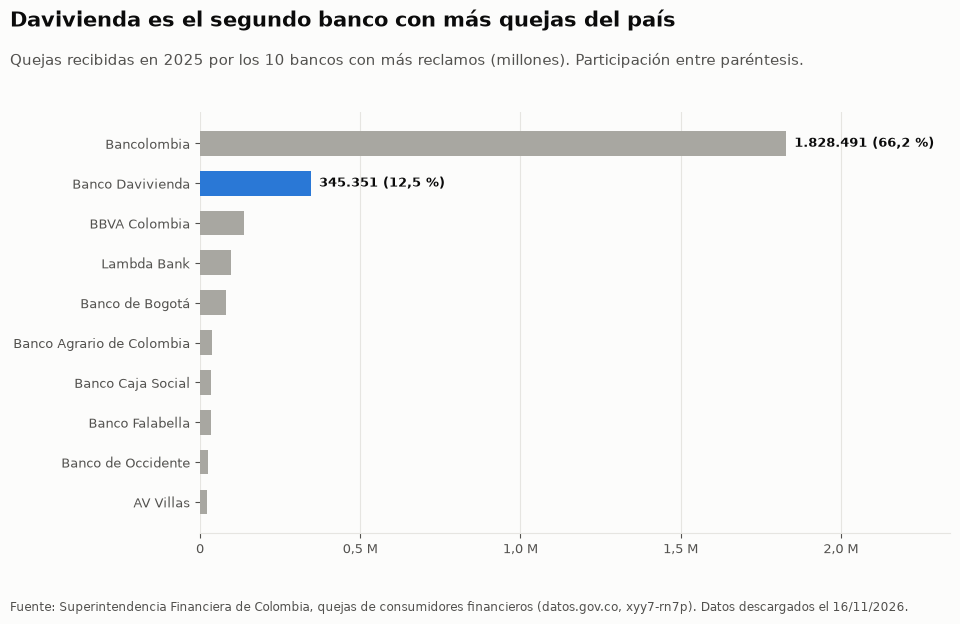

Total quejas a bancos 2025: 2,761,458
                                               participación_%   quejas
banco                                                                  
BANCOLOMBIA S.A.                                         66.21  1828491
BANCO DAVIVIENDA S.A.                                    12.51   345351
BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S.A.             4.97   137272
LAMBDA BANK S.A.                                          3.52    97066
BANCO DE BOGOTÁ S.A.                                      2.91    80448
BANCO AGRARIO DE COLOMBIA S.A.                            1.34    36996
BANCO CAJA SOCIAL S.A.                                    1.27    34935
BANCO FALABELLA S.A.                                      1.19    32863
BANCO DE OCCIDENTE                                        0.92    25447
BANCO COMERCIAL AV VILLAS S.A.                            0.81    22354


In [13]:
# ============================================================
# 6.1 ¿Quién recibe más quejas? Ranking de bancos en 2025 (último año completo)
# ============================================================
ANIO = 2025
ranking = (qb[qb["anio"] == ANIO].groupby("banco")["cantidad_quejas_recibidas"].sum()
           .sort_values(ascending=False).head(10))
total_anio = qb.loc[qb["anio"] == ANIO, "cantidad_quejas_recibidas"].sum()
datos = ranking.iloc[::-1]
colores = [AZUL if "DAVIVIENDA" in b else GRIS for b in datos.index]

fig, ax = plt.subplots(figsize=(10, 6.2))
fig.subplots_adjust(top=0.82, bottom=0.14, left=0.2, right=0.95)
ax.barh([nombre_banco(b) for b in datos.index], datos.values, color=colores, height=0.62)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: es_num(v / 1e6, 1) + " M" if v else "0"))
for j, (b, v) in enumerate(datos.items()):
    if "DAVIVIENDA" in b or v == datos.max():
        ax.annotate(f"{es_num(v)} ({es_num(100 * v / total_anio, 1)} %)", (v, j), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9.5, color=TEXTO, fontweight="bold")
ax.set_xlim(0, datos.max() * 1.28)
encabezado(fig, "Davivienda es el segundo banco con más quejas del país",
           f"Quejas recibidas en {ANIO} por los 10 bancos con más reclamos (millones). Participación entre paréntesis.")
pie(fig)
guardar(fig, "01_ranking_bancos")

print(f"Total quejas a bancos {ANIO}: {total_anio:,}")
print((100 * ranking / total_anio).round(2).rename("participación_%").to_frame().assign(quejas=ranking))

**Lectura.** En 2025 los bancos recibieron 2.761.458 quejas. Bancolombia concentra el 66,2 % (1.828.491) y Davivienda es segundo con el 12,5 % (345.351), unas 2,5 veces las quejas del tercero, BBVA Colombia (137.272).
*Cuidado al interpretar:* el volumen absoluto depende del número de clientes de cada banco, que no está en los datos; un banco grande tiende a recibir más quejas.

### 6.2 Evolución de las quejas de Davivienda

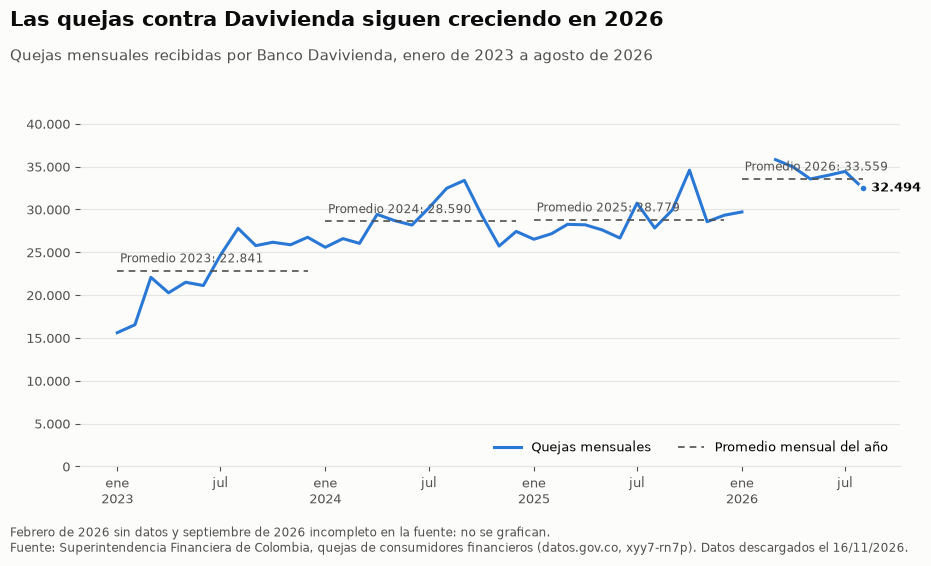

   anio  meses_completos  quejas_davivienda  promedio_mensual  \
0  2023               12           274088.0          22840.67   
1  2024               12           343076.0          28589.67   
2  2025               12           345351.0          28779.25   
3  2026                7           234914.0          33559.14   

   variacion_promedio_mensual_%  
0                           NaN  
1                         25.17  
2                          0.66  
3                         16.61  
Mínimo mensual: 15,609 (01/2023) | máximo: 35,811 (03/2026)


In [14]:
# ============================================================
# 6.2 Evolución mensual de las quejas de Davivienda
# ============================================================
serie = serie_mensual(dm, "quejas_davivienda")

fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(top=0.8, bottom=0.17, left=0.08, right=0.9)
ax.plot(serie.index, serie.values, color=AZUL, lw=2.2, label="Quejas mensuales de Davivienda")
# Promedio mensual de cada año (meses completos), como referencia horizontal
for _, fila in da.iterrows():
    anio = int(fila["anio"])
    x0, x1 = pd.Timestamp(f"{anio}-01-01"), min(pd.Timestamp(f"{anio}-12-01"), ultimo_mes)
    ax.hlines(fila["promedio_mensual"], x0, x1, color=TEXTO_2, lw=1.2, ls=(0, (4, 3)))
    ax.annotate(f"Promedio {anio}: {es_num(fila['promedio_mensual'])}", (x0, fila["promedio_mensual"]),
                xytext=(2, 6), textcoords="offset points", fontsize=8.8, color=TEXTO_2)
etiqueta_final(ax, serie.last_valid_index(), serie.dropna().iloc[-1], es_num(serie.dropna().iloc[-1]), AZUL)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: es_num(v)))
ax.set_ylim(0, serie.max() * 1.15)
eje_fechas(ax)
ax.legend(handles=[Line2D([], [], color=AZUL, lw=2.2, label="Quejas mensuales"),
                   Line2D([], [], color=TEXTO_2, lw=1.2, ls=(0, (4, 3)), label="Promedio mensual del año")],
          loc="lower right", ncol=2)
encabezado(fig, "Las quejas contra Davivienda siguen creciendo en 2026",
           "Quejas mensuales recibidas por Banco Davivienda, enero de 2023 a agosto de 2026")
pie(fig, "Febrero de 2026 sin datos y septiembre de 2026 incompleto en la fuente: no se grafican.")
guardar(fig, "02_evolucion_davivienda")

print(da[["anio", "meses_completos", "quejas_davivienda", "promedio_mensual", "variacion_promedio_mensual_%"]].round(2))
print(f"Mínimo mensual: {serie.min():,.0f} ({serie.idxmin():%m/%Y}) | máximo: {serie.max():,.0f} ({serie.idxmax():%m/%Y})")

**Lectura (pregunta 1).** El promedio mensual de quejas de Davivienda pasó de 22.841 en 2023 a 28.590 en 2024 (+25,2 %), se mantuvo en 2025 (28.779, +0,7 %) y volvió a subir en los siete meses completos de 2026 (33.559, +16,6 %). El mínimo del periodo fue enero de 2023 (15.609) y el máximo marzo de 2026 (35.811).

### 6.3 Participación frente a Bancolombia

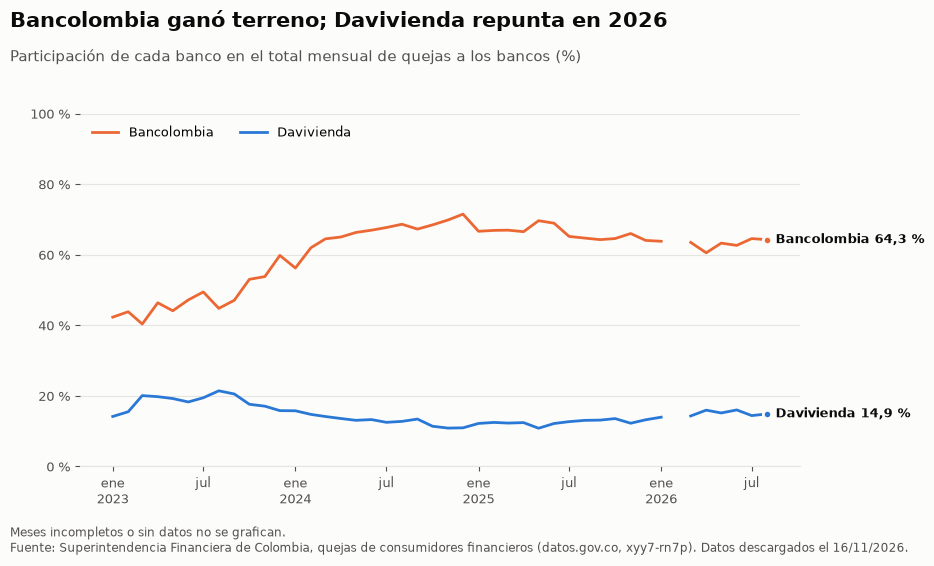

Quejas por año (meses completos):
       Bancolombia  Davivienda  total_bancos
fecha                                       
2023      730650.0    274088.0     1508243.0
2024     1777800.0    343076.0     2666499.0
2025     1828491.0    345351.0     2761458.0
2026      995440.0    234914.0     1573753.0
Participación % por año:
       Bancolombia  Davivienda
fecha                         
2023         48.44       18.17
2024         66.67       12.87
2025         66.21       12.51
2026         63.25       14.93


In [15]:
# ============================================================
# 6.3 Participación en las quejas a bancos: Davivienda frente a Bancolombia
# ============================================================
cod_bancolombia = int(qb.loc[qb["banco"].str.startswith("BANCOLOMBIA"), "codigo_entidad"].iloc[0])
part = bm.pivot_table(index="fecha", columns="codigo_entidad", values="participacion_%")
p_dav = part[COD_MARCA].reindex(cal["fecha"]).where(lambda s: s.index.isin(meses_ok))
p_bco = part[cod_bancolombia].reindex(cal["fecha"]).where(lambda s: s.index.isin(meses_ok))

fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(top=0.8, bottom=0.17, left=0.08, right=0.8)
ax.plot(p_bco.index, p_bco.values, color=NARANJA, label="Bancolombia")
ax.plot(p_dav.index, p_dav.values, color=AZUL, label="Davivienda")
for s, nombre, color in [(p_bco, "Bancolombia", NARANJA), (p_dav, "Davivienda", AZUL)]:
    etiqueta_final(ax, s.last_valid_index(), s.dropna().iloc[-1], f"{nombre} {es_num(s.dropna().iloc[-1], 1)} %", color)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_ylim(0, 100)
eje_fechas(ax)
ax.legend(loc="upper left", ncol=2)
encabezado(fig, "Bancolombia ganó terreno; Davivienda repunta en 2026",
           "Participación de cada banco en el total mensual de quejas a los bancos (%)")
pie(fig, "Meses incompletos o sin datos no se grafican.")
guardar(fig, "03_participacion_bancos")

anual = (bm[bm["fecha"].isin(meses_ok) & bm["codigo_entidad"].isin([COD_MARCA, cod_bancolombia])]
         .groupby([bm["fecha"].dt.year, "codigo_entidad"])["quejas"].sum().unstack())
anual.columns = ["Davivienda" if c == COD_MARCA else "Bancolombia" for c in anual.columns]
totales = bm[bm["fecha"].isin(meses_ok)].groupby(bm["fecha"].dt.year)["quejas"].sum()
print("Quejas por año (meses completos):"); print(anual.assign(total_bancos=totales))
print("Participación % por año:"); print((100 * anual.div(totales, axis=0)).round(2))

**Lectura (pregunta 1).** La caída de la participación de Davivienda entre 2023 (18,2 %) y 2025 (12,5 %) no indica una mejora de la marca: sus quejas subieron, pero las de Bancolombia crecieron mucho más (de 730.650 en 2023 a 1.777.800 en 2024), hasta concentrar dos tercios del total. En 2026 la tendencia se invierte: Bancolombia baja a 63,3 % y Davivienda sube a 14,9 %, es decir, **las quejas de Davivienda crecen más rápido que las del sector**, una señal de alerta para la marca.

### 6.4 Motivos de las quejas

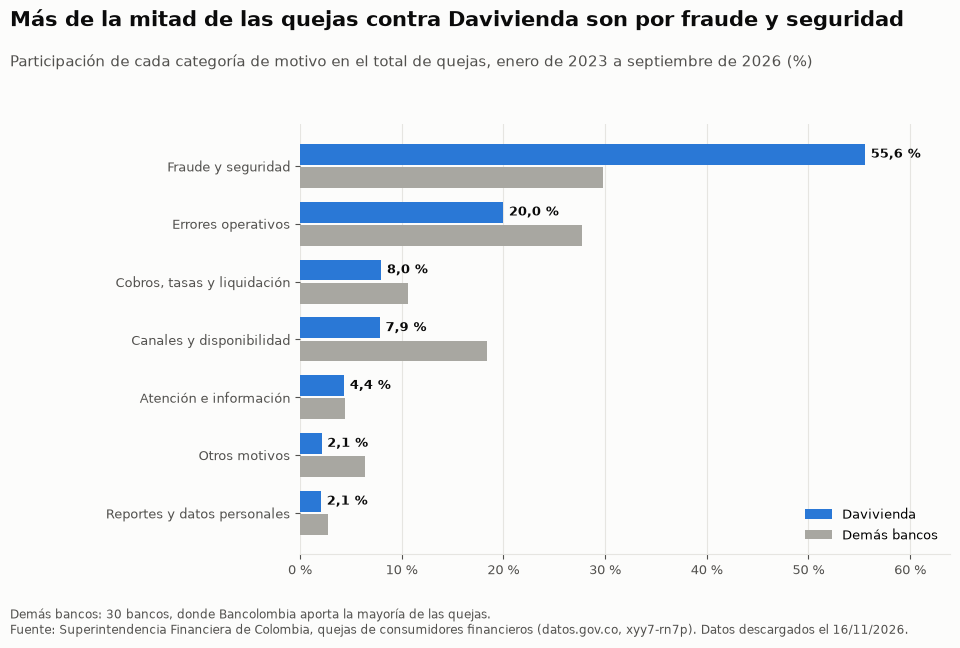

              categoria_motivo  quejas_davivienda  quejas_otros_bancos  %_davivienda  %_otros_bancos  diferencia_pp  indice_especializacion
0           Fraude y seguridad             666002              2177112         55.58           29.76          25.82                    1.87
1           Errores operativos             239569              2029600         19.99           27.74          -7.75                    0.72
2  Cobros, tasas y liquidación              95874               775058          8.00           10.59          -2.59                    0.76
3     Canales y disponibilidad              94237              1345001          7.86           18.39         -10.52                    0.43
4       Atención e información              52197               322569          4.36            4.41          -0.05                    0.99
5                Otros motivos              25446               468053          2.12            6.40          -4.27                    0.33
6  Reportes y datos 

In [16]:
# ============================================================
# 6.4 Composición de las quejas por motivo: Davivienda frente a los demás bancos
# ============================================================
tabla = dmot.copy()
tabla = tabla.sort_values("%_davivienda", ascending=False)
etiquetas = tabla.iloc[:, 0].tolist()[::-1]
y = np.arange(len(etiquetas))

fig, ax = plt.subplots(figsize=(10, 0.55 * len(etiquetas) + 2.6))
fig.subplots_adjust(top=1 - 1.25 / (0.55 * len(etiquetas) + 2.6), bottom=0.9 / (0.55 * len(etiquetas) + 2.6), left=0.3, right=0.95)
alto = 0.36
ax.barh(y + alto / 2 + 0.02, tabla["%_davivienda"].values[::-1], height=alto, color=AZUL, label="Davivienda")
ax.barh(y - alto / 2 - 0.02, tabla["%_otros_bancos"].values[::-1], height=alto, color=GRIS, label="Demás bancos")
for j, v in enumerate(tabla["%_davivienda"].values[::-1]):
    ax.annotate(f"{es_num(v, 1)} %", (v, y[j] + alto / 2 + 0.02), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=TEXTO, fontweight="bold")
ax.set_yticks(y, etiquetas)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_xlim(0, max(tabla["%_davivienda"].max(), tabla["%_otros_bancos"].max()) * 1.15)
ax.legend(loc="lower right")
encabezado(fig, "Más de la mitad de las quejas contra Davivienda son por fraude y seguridad", "Participación de cada categoría de motivo en el total de quejas, enero de 2023 a septiembre de 2026 (%)")
pie(fig, "Demás bancos: 30 bancos, donde Bancolombia aporta la mayoría de las quejas.")
guardar(fig, "04_motivos")

print(tabla.round(2).to_string())

**Lectura (pregunta 2).** El fraude y la seguridad explican el 55,6 % de las quejas de Davivienda, casi el doble que en los demás bancos (29,8 %): es el principal problema propio de la marca. En cambio, Davivienda tiene menos peso relativo en fallas de canales (7,9 % frente a 18,4 %) y en errores operativos (20,0 % frente a 27,7 %).

### 6.5 Evolución del fraude y la seguridad

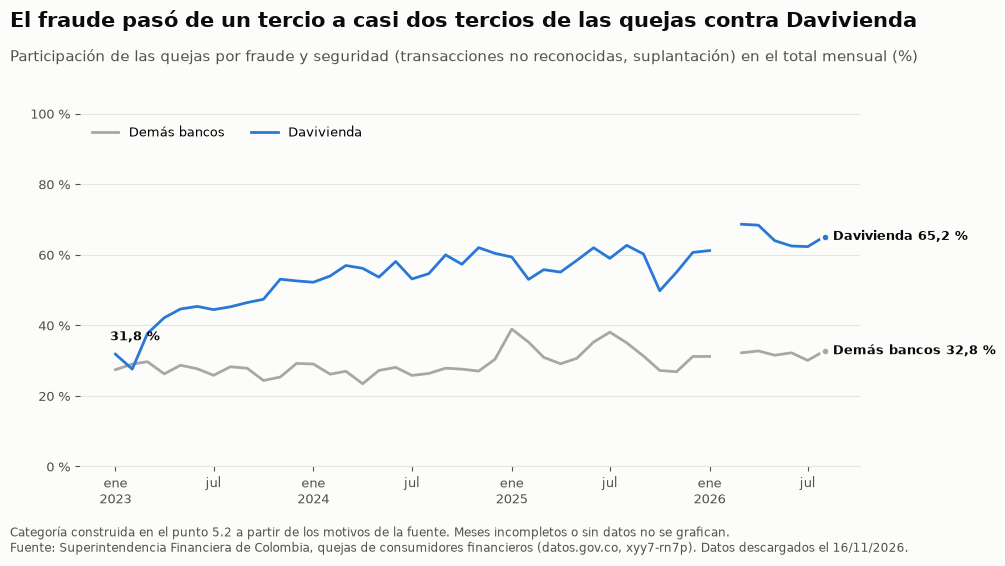

Peso % del fraude por año (meses completos):
       Demás bancos  Davivienda
fecha                          
2023          27.38       44.23
2024          27.16       56.53
2025          32.36       57.44
2026          31.78       64.69
Primer mes Davivienda: 31.81 % | rango de meses completos de 2026: 61.18 % a 68.64 %


In [17]:
# ============================================================
# 6.5 Evolución del peso del fraude y la seguridad
# ============================================================
fraude = (qb.assign(es_fraude=qb["categoria_motivo"].eq("Fraude y seguridad"))
          .groupby(["fecha", "es_davivienda"])
          .apply(lambda g: 100 * g.loc[g["es_fraude"], "cantidad_quejas_recibidas"].sum() / g["cantidad_quejas_recibidas"].sum(),
                 include_groups=False)
          .unstack())
f_dav = fraude[True].reindex(cal["fecha"]).where(lambda s: s.index.isin(meses_ok))
f_otros = fraude[False].reindex(cal["fecha"]).where(lambda s: s.index.isin(meses_ok))

fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(top=0.8, bottom=0.17, left=0.08, right=0.86)
ax.plot(f_otros.index, f_otros.values, color=GRIS, label="Demás bancos")
ax.plot(f_dav.index, f_dav.values, color=AZUL, label="Davivienda")
for s, nombre, color in [(f_dav, "Davivienda", AZUL), (f_otros, "Demás bancos", GRIS)]:
    etiqueta_final(ax, s.last_valid_index(), s.dropna().iloc[-1], f"{nombre} {es_num(s.dropna().iloc[-1], 1)} %", color)
ax.annotate(f"{es_num(f_dav.dropna().iloc[0], 1)} %", (f_dav.first_valid_index(), f_dav.dropna().iloc[0]),
            xytext=(-4, 10), textcoords="offset points", fontsize=9.5, color=TEXTO, fontweight="bold")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_ylim(0, 100)
eje_fechas(ax)
ax.legend(loc="upper left", ncol=2)
encabezado(fig, "El fraude pasó de un tercio a casi dos tercios de las quejas contra Davivienda",
           "Participación de las quejas por fraude y seguridad (transacciones no reconocidas, suplantación) en el total mensual (%)")
pie(fig, "Categoría construida en el punto 5.2 a partir de los motivos de la fuente. Meses incompletos o sin datos no se grafican.")
guardar(fig, "05_fraude_mensual")

anual_f = (qb[qb["fecha"].isin(meses_ok)].assign(fr=lambda d: d["categoria_motivo"].eq("Fraude y seguridad"))
           .groupby([qb["fecha"].dt.year, "es_davivienda"])
           .apply(lambda g: 100 * g.loc[g["fr"], "cantidad_quejas_recibidas"].sum() / g["cantidad_quejas_recibidas"].sum(),
                  include_groups=False).unstack().round(2))
anual_f.columns = ["Demás bancos", "Davivienda"]
print("Peso % del fraude por año (meses completos):"); print(anual_f)
print(f"Primer mes Davivienda: {f_dav.dropna().iloc[0]:.2f} % | rango de meses completos de 2026: "
      f"{f_dav[f_dav.index.year == 2026].min():.2f} % a {f_dav[f_dav.index.year == 2026].max():.2f} %")

**Lectura (pregunta 2).** El peso del fraude en las quejas de Davivienda creció cada año: 44,2 % en 2023, 56,5 % en 2024, 57,4 % en 2025 y 64,7 % en los meses completos de 2026 (entre 61,2 % y 68,6 % cada mes). En el primer mes de la serie era 31,8 %. En los demás bancos se mantuvo entre 27 % y 33 %.
*Cuidado al interpretar:* la fuente cambia su catálogo de motivos entre años; la categoría construida en el punto 5.2 agrupa los motivos de fraude para que la comparación en el tiempo sea más estable, pero las reglas deben ser validadas por el equipo.

### 6.6 Productos con más quejas

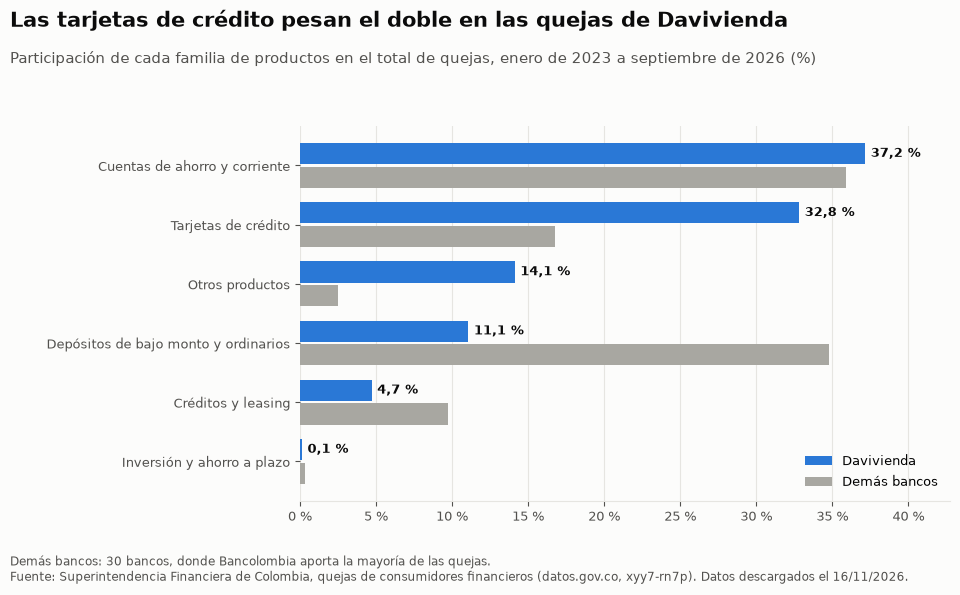

                       familia_producto  quejas_davivienda  quejas_otros_bancos  %_davivienda  %_otros_bancos  diferencia_pp  indice_especializacion
0         Cuentas de ahorro y corriente             445246              2626866         37.16           35.91           1.25                    1.03
1                   Tarjetas de crédito             393218              1228501         32.82           16.79          16.02                    1.95
2                       Otros productos             169204               183986         14.12            2.51          11.61                    5.61
3  Depósitos de bajo monto y ordinarios             132649              2543654         11.07           34.77         -23.70                    0.32
4                    Créditos y leasing              56423               709773          4.71            9.70          -4.99                    0.49
5            Inversión y ahorro a plazo               1539                22778          0.13            0

In [18]:
# ============================================================
# 6.6 Composición de las quejas por producto: Davivienda frente a los demás bancos
# ============================================================
tabla = dfam.copy()
tabla = tabla.sort_values("%_davivienda", ascending=False)
etiquetas = tabla.iloc[:, 0].tolist()[::-1]
y = np.arange(len(etiquetas))

fig, ax = plt.subplots(figsize=(10, 0.55 * len(etiquetas) + 2.6))
fig.subplots_adjust(top=1 - 1.25 / (0.55 * len(etiquetas) + 2.6), bottom=0.9 / (0.55 * len(etiquetas) + 2.6), left=0.3, right=0.95)
alto = 0.36
ax.barh(y + alto / 2 + 0.02, tabla["%_davivienda"].values[::-1], height=alto, color=AZUL, label="Davivienda")
ax.barh(y - alto / 2 - 0.02, tabla["%_otros_bancos"].values[::-1], height=alto, color=GRIS, label="Demás bancos")
for j, v in enumerate(tabla["%_davivienda"].values[::-1]):
    ax.annotate(f"{es_num(v, 1)} %", (v, y[j] + alto / 2 + 0.02), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=TEXTO, fontweight="bold")
ax.set_yticks(y, etiquetas)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_xlim(0, max(tabla["%_davivienda"].max(), tabla["%_otros_bancos"].max()) * 1.15)
ax.legend(loc="lower right")
encabezado(fig, "Las tarjetas de crédito pesan el doble en las quejas de Davivienda", "Participación de cada familia de productos en el total de quejas, enero de 2023 a septiembre de 2026 (%)")
pie(fig, "Demás bancos: 30 bancos, donde Bancolombia aporta la mayoría de las quejas.")
guardar(fig, "06_productos")

print(tabla.round(2).to_string())

**Lectura (pregunta 2).** Las tarjetas de crédito representan el 32,8 % de las quejas de Davivienda frente al 16,8 % en los demás bancos. Los depósitos de bajo monto pesan mucho menos en Davivienda (11,1 % frente a 34,8 %). "Otros productos" (14,1 % frente a 2,5 %) corresponde a una categoría genérica de la fuente ("Otros productos de Establecimientos de Crédito y SEDPE") que conviene revisar con la entidad.

### 6.7 Quejas radicadas ante la Superintendencia

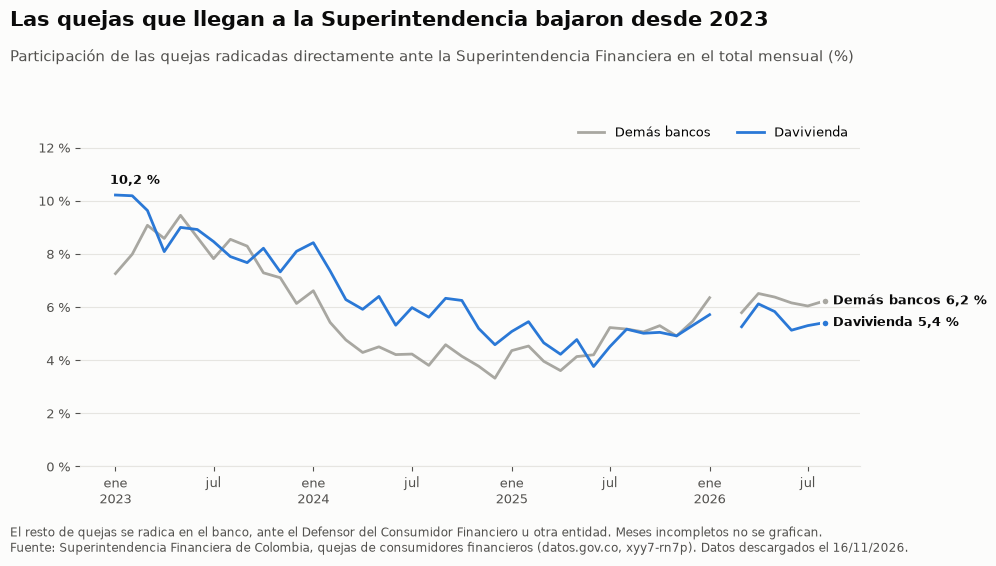

% de quejas ante la SFC por año (meses completos):
       Demás bancos  Davivienda
fecha                          
2023           7.88        8.51
2024           4.36        6.12
2025           4.66        4.83
2026           6.19        5.53


In [19]:
# ============================================================
# 6.7 Quejas que salen del banco: radicadas ante la Superintendencia Financiera
# ============================================================
sfc = (qb.assign(es_sfc=qb["instancia_recepcion"].eq("Superintendencia Financiera de Colombia"))
       .groupby(["fecha", "es_davivienda"])
       .apply(lambda g: 100 * g.loc[g["es_sfc"], "cantidad_quejas_recibidas"].sum() / g["cantidad_quejas_recibidas"].sum(),
              include_groups=False)
       .unstack())
s_dav = sfc[True].reindex(cal["fecha"]).where(lambda s: s.index.isin(meses_ok))
s_otros = sfc[False].reindex(cal["fecha"]).where(lambda s: s.index.isin(meses_ok))

fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(top=0.8, bottom=0.17, left=0.08, right=0.86)
ax.plot(s_otros.index, s_otros.values, color=GRIS, label="Demás bancos")
ax.plot(s_dav.index, s_dav.values, color=AZUL, label="Davivienda")
for s, nombre, color in [(s_dav, "Davivienda", AZUL), (s_otros, "Demás bancos", GRIS)]:
    etiqueta_final(ax, s.last_valid_index(), s.dropna().iloc[-1], f"{nombre} {es_num(s.dropna().iloc[-1], 1)} %", color)
ax.annotate(f"{es_num(s_dav.dropna().iloc[0], 1)} %", (s_dav.first_valid_index(), s_dav.dropna().iloc[0]),
            xytext=(-4, 8), textcoords="offset points", fontsize=9.5, color=TEXTO, fontweight="bold")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_ylim(0, max(s_dav.max(), s_otros.max()) * 1.3)
eje_fechas(ax)
ax.legend(loc="upper right", ncol=2)
encabezado(fig, "Las quejas que llegan a la Superintendencia bajaron desde 2023",
           "Participación de las quejas radicadas directamente ante la Superintendencia Financiera en el total mensual (%)")
pie(fig, "El resto de quejas se radica en el banco, ante el Defensor del Consumidor Financiero u otra entidad. Meses incompletos no se grafican.")
guardar(fig, "07_quejas_ante_sfc")

anual_s = (qb[qb["fecha"].isin(meses_ok)].assign(x=lambda d: d["instancia_recepcion"].eq("Superintendencia Financiera de Colombia"))
           .groupby([qb["fecha"].dt.year, "es_davivienda"])
           .apply(lambda g: 100 * g.loc[g["x"], "cantidad_quejas_recibidas"].sum() / g["cantidad_quejas_recibidas"].sum(),
                  include_groups=False).unstack().round(2))
anual_s.columns = ["Demás bancos", "Davivienda"]
print("% de quejas ante la SFC por año (meses completos):"); print(anual_s)

**Lectura (pregunta 3).** La proporción de quejas de Davivienda radicadas ante la Superintendencia bajó de 8,5 % en 2023 a 6,1 % en 2024 y 4,8 % en 2025, y subió levemente a 5,5 % en 2026; en el primer mes de la serie era 10,2 %. Los demás bancos siguen un patrón parecido (7,9 %, 4,4 %, 4,7 % y 6,2 %). Desde 2025 Davivienda se ubica en niveles similares o inferiores al resto, lo que sugiere que una proporción mayor de clientes resuelve su queja directamente con el banco. Los datos no permiten saber si esto se debe a una mejor atención o a otros factores.

### 6.8 Distribución territorial

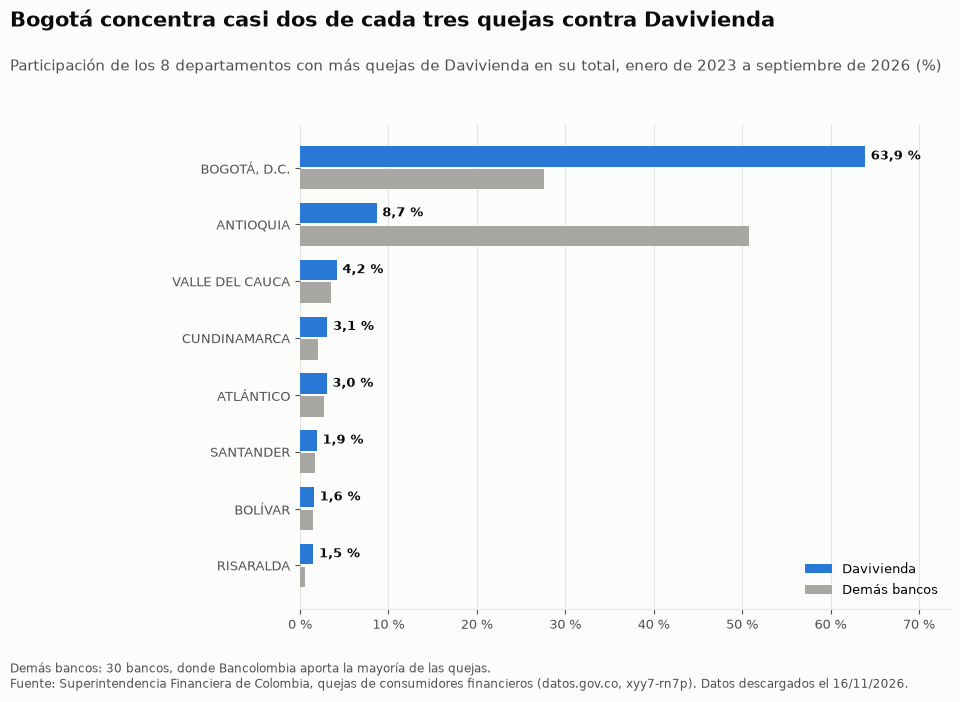

      departamento  quejas_davivienda  quejas_otros_bancos  %_davivienda  %_otros_bancos  diferencia_pp  indice_especializacion  grandes_empresas  ingresos_grandes_empresas  quejas_por_gran_empresa
0     BOGOTÁ, D.C.             765973              2020154         63.92           27.61          36.31                    2.31            4002.0                     955.61                   191.40
1        ANTIOQUIA             103987              3713406          8.68           50.76         -42.08                    0.17            1876.0                     318.65                    55.43
2  VALLE DEL CAUCA              49975               258111          4.17            3.53           0.64                    1.18             858.0                     129.44                    58.25
3     CUNDINAMARCA              37240               146113          3.11            2.00           1.11                    1.56             805.0                      90.31                    46.26
4        A

In [20]:
# ============================================================
# 6.8 Composición de las quejas por departamento: Davivienda frente a los demás bancos
# ============================================================
tabla = ddep.copy()
tabla = tabla.sort_values("%_davivienda", ascending=False).head(8)
etiquetas = tabla.iloc[:, 0].tolist()[::-1]
y = np.arange(len(etiquetas))

fig, ax = plt.subplots(figsize=(10, 0.55 * len(etiquetas) + 2.6))
fig.subplots_adjust(top=1 - 1.25 / (0.55 * len(etiquetas) + 2.6), bottom=0.9 / (0.55 * len(etiquetas) + 2.6), left=0.3, right=0.95)
alto = 0.36
ax.barh(y + alto / 2 + 0.02, tabla["%_davivienda"].values[::-1], height=alto, color=AZUL, label="Davivienda")
ax.barh(y - alto / 2 - 0.02, tabla["%_otros_bancos"].values[::-1], height=alto, color=GRIS, label="Demás bancos")
for j, v in enumerate(tabla["%_davivienda"].values[::-1]):
    ax.annotate(f"{es_num(v, 1)} %", (v, y[j] + alto / 2 + 0.02), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=TEXTO, fontweight="bold")
ax.set_yticks(y, etiquetas)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_xlim(0, max(tabla["%_davivienda"].max(), tabla["%_otros_bancos"].max()) * 1.15)
ax.legend(loc="lower right")
encabezado(fig, "Bogotá concentra casi dos de cada tres quejas contra Davivienda", "Participación de los 8 departamentos con más quejas de Davivienda en su total, enero de 2023 a septiembre de 2026 (%)")
pie(fig, "Demás bancos: 30 bancos, donde Bancolombia aporta la mayoría de las quejas.")
guardar(fig, "08_departamentos")

print(tabla.round(2).to_string())

**Lectura (pregunta 3).** Bogotá concentra el 63,9 % de las quejas de Davivienda, frente al 27,6 % en los demás bancos. Antioquia pesa poco en Davivienda (8,7 %) y mucho en los demás bancos (50,8 %), porque allí tiene su sede Bancolombia, que domina ese grupo. En el resto de departamentos la distribución es similar. Además, el 1,4 % de las quejas de Davivienda no tiene departamento registrado (punto 5.2).

### 6.9 Contexto complementario: la matriz y el tamaño económico del territorio

In [ ]:
# ============================================================
# 6.9 Contexto complementario (datos de las 10.000 empresas más grandes)
# ============================================================
# a) Quejas de Davivienda frente al desempeño de su matriz, Grupo Bolívar S.A. (años en común)
contexto_anual = da[["anio", "promedio_mensual", "participacion_%", "ingresos_operacionales_matriz",
                     "ganancia_p_rdida_matriz", "total_activos_matriz"]].dropna()
display(Markdown("#### Quejas de Davivienda y cifras de Grupo Bolívar S.A. (años en común)"))
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(contexto_anual)

# b) Quejas de Davivienda por cada gran empresa del departamento (aproximación del tamaño económico)
top = (ddep[ddep["departamento"] != "SIN INFORMACIÓN"].nlargest(10, "quejas_davivienda")
       .sort_values("quejas_por_gran_empresa"))
mediana = ddep.loc[ddep["grandes_empresas"] >= 20, "quejas_por_gran_empresa"].median()
etiquetas = [d.title().replace(", D.C.", ", D.C.").replace(" Del ", " del ") for d in top["departamento"]]
colores = [AZUL if v > mediana else GRIS for v in top["quejas_por_gran_empresa"]]

fig, ax = plt.subplots(figsize=(10, 6.2))
fig.subplots_adjust(top=0.8, bottom=0.17, left=0.2, right=0.93)
ax.barh(etiquetas, top["quejas_por_gran_empresa"], color=colores, height=0.62)
ax.axvline(mediana, color=TEXTO_2, lw=1.2, ls=(0, (4, 3)))
ax.annotate(f"Mediana departamental: {es_num(mediana, 1)}", (mediana, len(top) - 0.4), xytext=(4, 0),
            textcoords="offset points", fontsize=9, color=TEXTO_2)
for j, v in enumerate(top["quejas_por_gran_empresa"]):
    ax.annotate(es_num(v, 1), (v, j), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9.5,
                color=TEXTO, fontweight="bold")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, top["quejas_por_gran_empresa"].max() * 1.15)
encabezado(fig, "Boyacá, Bogotá y Caldas reciben más quejas de las que su tamaño sugiere",
           "Quejas de Davivienda (2023–2026) por cada gran empresa del departamento (2025), 10 departamentos con más quejas")
pie(fig, "Gran empresa: una de las 10.000 más grandes del país (6cat-2gcs). Azul: por encima de la mediana departamental.")
guardar(fig, "09_quejas_por_gran_empresa")

print(f"Mediana de quejas por gran empresa (departamentos con al menos 20 grandes empresas): {mediana:.1f}")
print(top[["departamento", "quejas_davivienda", "grandes_empresas", "quejas_por_gran_empresa"]]
      .sort_values("quejas_por_gran_empresa", ascending=False).round(1).to_string(index=False))

**Lectura (contexto de las preguntas 1 y 3).**
- **Territorio.** Entre los 10 departamentos con más quejas de Davivienda, Boyacá (222,7 quejas por gran empresa), Bogotá (191,4) y Caldas (134,6) están muy por encima de la mediana departamental (85,2): reciben más quejas de las que su tamaño empresarial sugiere. Antioquia (55,4), Valle del Cauca (58,2) y Cundinamarca (46,3) están por debajo. El indicador usa el número de grandes empresas como aproximación del tamaño económico; no mide clientes del banco.
- **Matriz.** Entre 2023 y 2025 los ingresos de Grupo Bolívar pasaron de 1,09 a 1,58 y luego a 0,94, y su ganancia de 1,49 a 1,80 y a 0,88, mientras el promedio mensual de quejas subió en 2024 y se mantuvo en 2025. Con tres años en común no se puede establecer una relación entre ambas series: sirve como contexto del desempeño del grupo. La unidad de los montos no está documentada en la fuente.

### Síntesis de la visualización
| Pregunta | Respuesta preliminar | Gráficos |
|---|---|---|
| 1. Evolución y posición frente al sector | Las quejas de Davivienda crecen (promedio mensual de 22.841 en 2023 a 33.559 en 2026) y en 2026 crecen más rápido que las del sector. | 6.1, 6.2, 6.3 |
| 2. Causas de la insatisfacción | El fraude y la seguridad son el problema propio de la marca (55,6 % frente a 29,8 %) y su peso aumenta; las tarjetas de crédito pesan el doble que en los demás bancos. | 6.4, 6.5, 6.6 |
| 3. Gestión de la queja y territorio | Las quejas que llegan a la Superintendencia bajaron desde 2023 y hoy están en niveles similares al resto; Bogotá concentra casi dos tercios de las quejas, y Boyacá, Bogotá y Caldas reciben más quejas de las que su tamaño empresarial sugiere. | 6.7, 6.8, 6.9 |
| Contexto (datos complementarios) | El desempeño de Grupo Bolívar entre 2023 y 2025 no muestra una relación clara con las quejas; sirve como contexto, no como explicación. | 6.9 |

Los gráficos están en `work/figuras` (PNG, 200 dpi) para la presentación.

## 7. Trabajo en equipo
- Reglas del equipo.
- Reuniones realizadas (asistentes y actividades).
- Evaluación del trabajo (autoevaluación y evaluación de pares).